# CHE1147 — Molecular Lipophilicity Prediction


This notebook compares Ridge, Random Forest, and XGBoost with three feature sets: Full RDKit, Reduced RDKit, and PhysChem11.

We load and clean the data, check descriptor outliers, and apply log1p to Ipc. We then examine descriptor correlations and redundancy and prepare PhysChem11. After these EDA steps, we create the stratified train/test split and five shared CV folds.

All nine configurations use the same cleaned molecules, train/test split, and CV folds. We divide logD into bins only to create the splits. The models predict the original continuous logD values.

We select model parameters and the final configuration using CV.


# **Package installation and environment**

We use RDKit 2025.9.4, XGBoost 3.1.3, and scikit-learn 1.8.0. Run the installation cells before importing these packages. The model settings and parameter grids are the same as before. We save the package versions used in this run.


In [57]:
# Pin the RDKit version used in the full-data validation run
%pip -q install rdkit==2025.9.4


In [2]:
%pip -q install xgboost==3.1.3 scikit-learn==1.8.0

import xgboost
import sklearn

print("XGBoost version:", xgboost.__version__)
print("scikit-learn version:", sklearn.__version__)

# Record the environment used for this run
import json
import platform
from pathlib import Path
import rdkit
import numpy as np
import pandas as pd

# Use the same log1p(Ipc) transformation in EDA and the six RDKit models.
USE_IPC_LOG = True
output_dir = Path(
    "LIPO_Stratified_Results_Ipc_log1p" if USE_IPC_LOG
    else "LIPO_Stratified_Results_Ipc_raw"
)
output_dir.mkdir(exist_ok=True)

environment = {
    "python": platform.python_version(),
    "rdkit": rdkit.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "ipc_log_enabled": USE_IPC_LOG
}

(output_dir / "environment.json").write_text(
    json.dumps(environment, indent=2), encoding="utf-8"
)
print("Environment saved to:", output_dir / "environment.json")


XGBoost version: 3.1.3
scikit-learn version: 1.8.0
Environment saved to: LIPO_Stratified_Results_Ipc_log1p/environment.json


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen


# 1. Data Loading & Initial EDA

## 1.1 DeepChem Data Loading

The team load the data from DeepChem. The data contains 4200 molecular without duplication. The dataset contains three columns: `CMPD_CHEMBLID`, a compound identifier; `smiles`, SMILES representation of the molecular structure; and `exp`, the experimental logD value.

In [50]:
from pathlib import Path
import hashlib

LIPO_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/Lipophilicity.csv"

# Read the original CSV locally when available; otherwise use the original URL.
# In Colab, upload the CSV to the current session before running this cell.
local_candidates = [
    Path("Lipophilicity_original (10).csv"),
    Path("Lipophilicity_original (12).csv"),
    Path("Lipophilicity_original (5).csv"),
    Path("Lipophilicity_original.csv"),
    Path("Lipophilicity.csv")
]
local_csv = next((p for p in local_candidates if p.is_file()), None)
source = local_csv if local_csv is not None else LIPO_URL
try:
    df = pd.read_csv(source)
except Exception as exc:
    raise RuntimeError(
        "Could not read LIPO data. Upload Lipophilicity_original.csv "
        "or Lipophilicity.csv to this notebook's working folder."
    ) from exc

required_columns = ["CMPD_CHEMBLID", "exp", "smiles"]
assert set(required_columns).issubset(df.columns)
assert df[required_columns].notna().all().all()
assert df["CMPD_CHEMBLID"].is_unique
assert df["smiles"].is_unique
assert np.isfinite(df["exp"].to_numpy(dtype=float)).all()
print("Data source:", source)

# Record the exact input bytes when reading a local file.
source_record = {"source": str(source), "rows": len(df)}
if local_csv is not None:
    source_record["sha256"] = hashlib.sha256(local_csv.read_bytes()).hexdigest()
(output_dir / "data_source.json").write_text(
    json.dumps(source_record, indent=2), encoding="utf-8"
)
df.head()


Data source: Lipophilicity_original.csv


,CMPD_CHEMBLID,exp,smiles
0,CHEMBL596271,3.54,Cn1c(CN2CCN(CC2)c3ccc(Cl)cc3)nc4ccccc14
1,CHEMBL1951080,-1.18,COc1cc(OC)c(cc1NC(=O)CSCC(=O)O)S(=O)(=O)N2C(C)...
2,CHEMBL1771,3.69,COC(=O)[C@@H](N1CCc2sccc2C1)c3ccccc3Cl
3,CHEMBL234951,3.37,OC[C@H](O)CN1C(=O)C(Cc2ccccc12)NC(=O)c3cc4cc(C...
4,CHEMBL565079,3.10,Cc1cccc(C[C@H](NC(=O)c2cc(nn2C)C(C)(C)C)C(=O)N...


In [51]:
# Create a backup
raw_data = df[["CMPD_CHEMBLID", "exp", "smiles"]].copy()

print("Original dataset shape:", raw_data.shape)
raw_data.to_csv("Lipophilicity_original.csv", index=False)


Original dataset shape: (4200, 3)


In [52]:
# Check the data quality, especially for missing values
print("Dataset shape:")
print(df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicated rows:")
print(df.duplicated().sum())

print("\nDuplicated SMILES:")
print(df["smiles"].duplicated().sum())


Dataset shape:
(4200, 3)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CMPD_CHEMBLID  4200 non-null   object 
 1   exp            4200 non-null   float64
 2   smiles         4200 non-null   object 
dtypes: float64(1), object(2)
memory usage: 98.6+ KB

Missing values:
CMPD_CHEMBLID    0
exp              0
smiles           0
dtype: int64

Duplicated rows:
0

Duplicated SMILES:
0


In [53]:
# Examine target statistics
print("Target variable: exp")

print("\nSummary statistics:")
print(df["exp"].describe())

print("\nMedian:")
print(df["exp"].median())

print("\nSkewness:")
print(df["exp"].skew())


Target variable: exp

Summary statistics:
count    4200.000000
mean        2.186336
std         1.203004
min        -1.500000
25%         1.410000
50%         2.360000
75%         3.100000
max         4.500000
Name: exp, dtype: float64

Median:
2.36

Skewness:
-0.5822183436660706


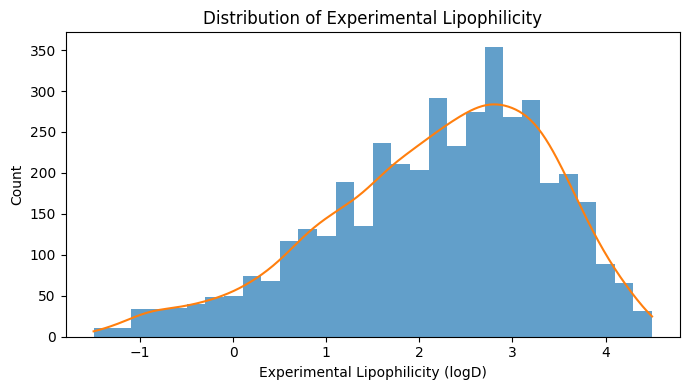

In [54]:
# Draw a histogram to see the distribution of the data
from scipy.stats import gaussian_kde

plt.figure(figsize=(7, 4))
counts, bin_edges, _ = plt.hist(df["exp"], bins=30, alpha=0.7)

# Keep the density curve from the original histogram, scaled to molecule counts
kde = gaussian_kde(df["exp"].to_numpy(dtype=float))
grid = np.linspace(df["exp"].min(), df["exp"].max(), 300)
plt.plot(grid, kde(grid) * len(df) * (bin_edges[1] - bin_edges[0]))
plt.xlabel("Experimental Lipophilicity (logD)")
plt.ylabel("Count")
plt.title("Distribution of Experimental Lipophilicity")
plt.tight_layout()
plt.show()
plt.close()


The experimental lipophilicity values are mainly concentrated between approximately 1 and 4, with a peak around 2.5–3.5. The distribution is moderately left-skewed.

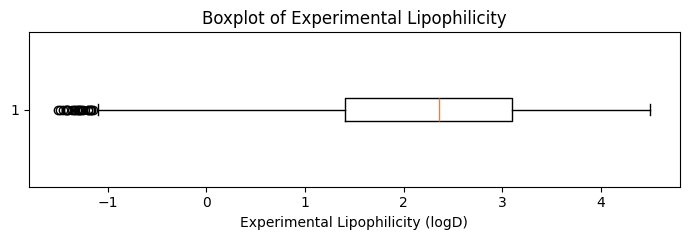

In [55]:
# Boxplot to see the median, quartiles and outliers
plt.figure(figsize=(7, 2.5))
plt.boxplot(df["exp"].to_numpy(), orientation="horizontal")
plt.xlabel("Experimental Lipophilicity (logD)")
plt.title("Boxplot of Experimental Lipophilicity")
plt.tight_layout()
plt.show()
plt.close()


In [56]:
# Use IQR to indentify the outliers
Q1 = df["exp"].quantile(0.25)
Q3 = df["exp"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["exp"] < lower_bound) |
    (df["exp"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("\nLower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nNumber of potential outliers:", len(outliers))

print("\nPercentage of potential outliers:")
print(len(outliers) / len(df) * 100)

outliers.head(10)


Q1: 1.41
Q3: 3.1
IQR: 1.6900000000000002

Lower bound: -1.1250000000000002
Upper bound: 5.635

Number of potential outliers: 22

Percentage of potential outliers:
0.5238095238095238


,CMPD_CHEMBLID,exp,smiles
1,CHEMBL1951080,-1.18,COc1cc(OC)c(cc1NC(=O)CSCC(=O)O)S(=O)(=O)N2C(C)...
51,CHEMBL484901,-1.17,NC(Cc1c[nH]c2ccccc12)C(=O)O
160,CHEMBL443320,-1.34,Cc1ccc(NC(=N)N)cc1C
712,CHEMBL1715893,-1.40,CC1CC(CN)CC(CO)C1
875,CHEMBL1349,-1.30,CC(C)[C@H](N)C(=O)OCCOCn1cnc2C(=O)N=C(N)Nc12
1014,CHEMBL211456,-1.15,CN[C@@H](C)[C@H](O)c1ccccc1
1121,CHEMBL424,-1.36,OC(=O)c1ccccc1O
1299,CHEMBL1752,-1.25,CN1C(=O)N(C)c2ncn(CC(O)CO)c2C1=O
1344,CHEMBL1230668,-1.45,CN(C)c1cccc2c(cccc12)S(=O)(=O)N(C)CC(=O)O
1367,CHEMBL2331742,-1.28,CC1=CN([C@H]2CCCN(C2)S(=O)(=O)c3ccc(C(=O)O)c(O...


## 1.2 RDKit Descriptor Calculation


In [11]:
# apply Chem.MolFromSmiles for each Smiles string and stores the resulting RDKit molecule object in a new mol column.
df["mol"] = df["smiles"].apply(Chem.MolFromSmiles)

invalid_molecules = df["mol"].isnull().sum()

print("Total molecules:", len(df))
print("Valid molecules:", len(df) - invalid_molecules)
print("Invalid molecules:", invalid_molecules)


Total molecules: 4200
Valid molecules: 4200
Invalid molecules: 0


In [12]:
# See the descriptors
from rdkit.Chem import Descriptors

descriptor_list = Descriptors._descList

print("Number of RDKit descriptors:", len(descriptor_list))

print("\nFirst 20 descriptor names:")
print([name for name, func in descriptor_list[:20]])


Number of RDKit descriptors: 217

First 20 descriptor names:
['MaxAbsEStateIndex', 'MaxEStateIndex', 'MinAbsEStateIndex', 'MinEStateIndex', 'qed', 'SPS', 'MolWt', 'HeavyAtomMolWt', 'ExactMolWt', 'NumValenceElectrons', 'NumRadicalElectrons', 'MaxPartialCharge', 'MinPartialCharge', 'MaxAbsPartialCharge', 'MinAbsPartialCharge', 'FpDensityMorgan1', 'FpDensityMorgan2', 'FpDensityMorgan3', 'BCUT2D_MWHI', 'BCUT2D_MWLOW']


In [13]:
# Calculate RDKit molecular descriptors for each molecule, each row is a molecule, and each column is an input feature
def calculate_all_descriptors(mol):
    results = {}

    for name, func in descriptor_list:
        try:
            results[name] = func(mol)
        except Exception:
            results[name] = np.nan

    return pd.Series(results)


descriptor_df = df["mol"].apply(calculate_all_descriptors)

print("Descriptor matrix shape:", descriptor_df.shape)

display(descriptor_df.head())


Descriptor matrix shape: (4200, 217)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,5.976320,5.976320,0.790958,0.790958,0.728444,16.000000,340.858,319.690,340.145474,124.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,13.847757,13.847757,0.083663,-4.060285,0.545587,15.484848,494.591,468.383,494.118143,178.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,12.294248,12.294248,0.262241,-0.447454,0.807761,16.285714,321.829,305.701,321.059027,110.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,12.966133,12.966133,0.046181,-1.063518,0.506650,17.607143,419.890,401.746,419.070655,146.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,12.834652,12.834652,0.112199,-0.795707,0.747686,12.142857,381.480,354.264,381.216475,148.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 1.3 Data Cleaning

The team used RDKit to calculate 217 molecular descriptors from the SMILES strings. One molecule is removed due to missing values in 12 descriptors. We removed nine constant descriptors as they have the same value across all molecules and cannot distinguish between each sample. In the end, 4199 molecules and 208 candidate descriptors are left in our database.


In [14]:
# Check the calculated descriptors
# Replace infinity values with NaN first
descriptor_df_cleancheck = descriptor_df.replace([np.inf, -np.inf], np.nan)

# Build a quality summary for every descriptor
feature_quality = pd.DataFrame({
    "Missing": descriptor_df_cleancheck.isnull().sum(),
    "UniqueValues": descriptor_df_cleancheck.nunique()
})

print("Total descriptors:", descriptor_df.shape[1])

print("\nDescriptors with missing values:")
print((feature_quality["Missing"] > 0).sum())

print("\nConstant descriptors:")
print((feature_quality["UniqueValues"] <= 1).sum())

display(
    feature_quality.sort_values(
        ["Missing", "UniqueValues"],
        ascending=[False, True]
    ).head(30)
)


Total descriptors: 217

Descriptors with missing values:
12

Constant descriptors:
9


,Missing,UniqueValues
MaxAbsPartialCharge,1,3343
MinPartialCharge,1,3379
MaxPartialCharge,1,3542
MinAbsPartialCharge,1,3601
BCUT2D_MWLOW,1,4099
BCUT2D_LOGPLOW,1,4100
BCUT2D_MWHI,1,4101
BCUT2D_CHGHI,1,4101
BCUT2D_CHGLO,1,4101
BCUT2D_LOGPHI,1,4101


In [15]:
# Identify molecules with missing descriptors
# Convert inf to NaN
descriptor_df_check = descriptor_df.replace([np.inf, -np.inf], np.nan)

# Find molecules that have at least one missing descriptor
rows_with_missing = descriptor_df_check.isnull().any(axis=1)

print("Number of molecules with at least one missing descriptor:")
print(rows_with_missing.sum())

print("\nMolecules with missing descriptors:")
display(
    df.loc[rows_with_missing, ["CMPD_CHEMBLID", "exp", "smiles"]]
)

print("\nDescriptors with missing values:")
missing_counts = descriptor_df_check.isnull().sum()
display(missing_counts[missing_counts > 0].sort_values(ascending=False))


Number of molecules with at least one missing descriptor:
1

Molecules with missing descriptors:


,CMPD_CHEMBLID,exp,smiles
1561,CHEMBL51085,3.31,O=C1N([Se]c2ccccc12)c3ccccc3



Descriptors with missing values:


,0
MaxPartialCharge,1
MinPartialCharge,1
MaxAbsPartialCharge,1
MinAbsPartialCharge,1
BCUT2D_MWHI,1
BCUT2D_MWLOW,1
BCUT2D_CHGHI,1
BCUT2D_CHGLO,1
BCUT2D_LOGPHI,1
BCUT2D_LOGPLOW,1


In [16]:
# Remove the one molecule with missing descriptor values
valid_rows = ~rows_with_missing

df_clean = df.loc[valid_rows].reset_index(drop=True)
descriptor_clean = descriptor_df_check.loc[valid_rows].reset_index(drop=True)

print("Samples before cleaning:", len(df))
print("Samples after cleaning:", len(df_clean))


Samples before cleaning: 4200
Samples after cleaning: 4199


We calculate descriptors using the same RDKit functions as before. We remove molecules with missing or infinite descriptor values. We keep the target values outside the IQR limits because these values alone do not show that a measurement is wrong.


## 1.4 Descriptor Outlier Analysis

We check all descriptors using IQR limits and the 99th percentile (P99). The IQR count shows how many values lie below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR. Max/P99 shows how large the maximum is compared with the upper end of most values.

We skip the IQR count when IQR is zero and calculate Max/P99 only when P99 is positive. These checks flag unusual values; they do not prove that a molecule or measurement is wrong.

In [17]:
# Check the distributions of all raw descriptors
q1 = descriptor_clean.quantile(0.25)
q3 = descriptor_clean.quantile(0.75)
iqr = q3 - q1
p99 = descriptor_clean.quantile(0.99)

outside_iqr = (
    descriptor_clean.lt(q1 - 1.5 * iqr)
    | descriptor_clean.gt(q3 + 1.5 * iqr)
)

descriptor_outliers = pd.DataFrame({
    "Median": descriptor_clean.median(),
    "IQR": iqr,
    "P99": p99,
    "Maximum": descriptor_clean.max(),
    "IQR_Outliers": outside_iqr.sum().where(iqr > 0).astype("Int64"),
    "Max_to_P99": descriptor_clean.max() / p99.where(p99 > 0)
}).sort_values("Max_to_P99", ascending=False)

print("Descriptors with the largest maximum-to-P99 ratios:")
with pd.option_context("display.max_columns", None, "display.float_format", "{:.4g}".format):
    display(descriptor_outliers.head(10))

# Identify molecules with the largest values of the top-ranked descriptor
outlier_descriptor = descriptor_outliers.index[0]
outlier_indices = descriptor_clean[outlier_descriptor].nlargest(5).index
outlier_molecules = df_clean.loc[
    outlier_indices, ["CMPD_CHEMBLID", "exp", "smiles"]
].copy()
outlier_molecules[outlier_descriptor] = descriptor_clean.loc[
    outlier_indices, outlier_descriptor
]

print("\nDescriptor to inspect:", outlier_descriptor)
display(outlier_molecules)

descriptor_outliers.to_csv(
    output_dir / "LIPO_Descriptor_Outlier_Summary.csv", index_label="Descriptor"
)
outlier_molecules.to_csv(
    output_dir / "LIPO_Descriptor_Outlier_Molecules.csv", index=False
)


Descriptors with the largest maximum-to-P99 ratios:


,Median,IQR,P99,Maximum,IQR_Outliers,Max_to_P99
Ipc,1.911e+06,2.093e+07,5.467e+09,7.394e+30,712,1.353e+21
fr_C_O,1,1,3,20,111,6.667
fr_unbrch_alkane,0,0,1,6,<NA>,6
fr_C_O_noCOO,1,1,3,16,100,5.333
EState_VSA1,5.907,11.96,50.64,261.5,204,5.163
VSA_EState2,16.74,14.56,53.75,276.1,64,5.136
fr_allylic_oxid,0,0,1,5,<NA>,5
NHOHCount,2,2,5,25,10,5
NumAmideBonds,1,1,3,14,115,4.667
fr_amide,1,1,3,14,115,4.667



Descriptor to inspect: Ipc


,CMPD_CHEMBLID,exp,smiles,Ipc
3591,CHEMBL387675,-0.94,CCCCCCCCCC(=O)N[C@@H](Cc1c[nH]c2ccccc12)C(=O)N...,7.394439e+30
1397,CHEMBL1200558,-0.46,CC[C@H](C)[C@H](N)C1=N[C@@H](CS1)C(=O)N[C@@H](...,3.896833e+23
1236,CHEMBL2170837,4.20,CCn1c(C)c(C(=O)O)c(c2cccc(c2)N3CCN(CC3)c4ccc(N...,5.359436e+15
905,CHEMBL443684,0.64,CC1(C)CCC(=C(CN2CCN(CC2)c3ccc(cc3)C(=O)NS(=O)(...,1.293338e+14
1645,CHEMBL3545252,3.40,O.O.O.CC(=O)O[C@@]12CO[C@@H]1C[C@H](O)[C@]3(C)...,1.464012e+12


## 1.5 Ipc Log Transformation

Ipc has a very large maximum compared with its P99. We apply log1p(Ipc), which is log(1 + Ipc), to compress this wide range while keeping the order of the values. This treats the descriptor's scale; it does not remove the molecule or change its experimental logD.

The next EDA steps use a transformed copy called `descriptor_eda`. We keep `descriptor_clean` unchanged. Later, each RDKit model applies the same transformation once to its raw input.


In [18]:
from sklearn.preprocessing import FunctionTransformer

# Apply the Ipc transformation without changing the raw input matrix
def transform_ipc(X, apply_log=True):
    X = X.copy()
    if apply_log:
        if (X["Ipc"] < 0).any():
            raise ValueError("Ipc contains negative values.")
        X["Ipc"] = np.log1p(X["Ipc"])
    return X


# Use one transformed copy for the following EDA steps
descriptor_eda = transform_ipc(descriptor_clean, apply_log=USE_IPC_LOG)

ipc_scale_summary = pd.DataFrame({
    "Raw_Ipc": descriptor_clean["Ipc"].describe(percentiles=[0.5, 0.99]),
    "Log1p_Ipc": descriptor_eda["Ipc"].describe(percentiles=[0.5, 0.99])
})

print("Ipc values before and after log1p:")
display(ipc_scale_summary)

# Verify the transformation and keep all other descriptors unchanged
assert np.isfinite(descriptor_eda.to_numpy(dtype=float)).all()
assert descriptor_eda.drop(columns="Ipc").equals(
    descriptor_clean.drop(columns="Ipc")
)
assert np.allclose(descriptor_eda["Ipc"], np.log1p(descriptor_clean["Ipc"]))


Ipc values before and after log1p:


,Raw_Ipc,Log1p_Ipc
count,4.199000e+03,4199.000000
mean,1.761000e+27,14.286494
std,1.141123e+29,3.802151
min,4.667048e+01,3.864312
50%,1.910721e+06,14.462991
99%,5.467071e+09,22.421969
max,7.394439e+30,71.078281


## 1.6 Descriptor Correlation Analysis

### Descriptor Relationships with logD


We first examine each descriptor's Pearson correlation with logD. We use absolute correlation to rank both positive and negative relationships. This ranking is for description only.


In [19]:
# Remove zero-variance descriptors for the full-dataset EDA preview only
nonconstant_cols = [
    col for col in descriptor_eda.columns
    if descriptor_eda[col].nunique() > 1
]
descriptor_final_pool = descriptor_eda[nonconstant_cols].copy()

print("Descriptors before constant removal:", descriptor_eda.shape[1])
print("Descriptors after constant removal:", descriptor_final_pool.shape[1])
print("Constant descriptors removed:",
      descriptor_eda.shape[1] - descriptor_final_pool.shape[1])


Descriptors before constant removal: 217
Descriptors after constant removal: 208
Constant descriptors removed: 9


In [20]:
# Calculate Pearson correlation between every descriptor and exp
y_clean = df_clean["exp"]

correlations = descriptor_final_pool.corrwith(y_clean)

# Remove undefined correlations
correlations = correlations.dropna()

correlation_ranking = pd.DataFrame({
    "Pearson_r": correlations,
    "Abs_Pearson_r": correlations.abs()
}).sort_values(
    "Abs_Pearson_r",
    ascending=False
)

display(correlation_ranking.head(30).round(3))


,Pearson_r,Abs_Pearson_r
MolLogP,0.416,0.416
fr_COO2,-0.354,0.354
fr_COO,-0.354,0.354
NumAromaticRings,0.298,0.298
fr_Al_COO,-0.282,0.282
RingCount,0.280,0.280
BalabanJ,-0.263,0.263
FpDensityMorgan1,-0.255,0.255
VSA_EState6,0.240,0.240
SlogP_VSA6,0.237,0.237


This ranking uses all cleaned molecules after the Ipc transformation. It does not select the model inputs.

We next check correlations between descriptors. These relationships show where descriptors may contain similar information. The reduction rule uses these descriptor-to-descriptor correlations, not the ranking against logD.


### Correlations Between Descriptors

In [21]:
import numpy as np
import pandas as pd

# Check descriptor relationships after log1p(Ipc)
X_corr = descriptor_eda.copy()

# Remove constant descriptors
X_corr = X_corr.loc[:, X_corr.nunique() > 1]

# Calculate correlations among all candidate descriptors
corr_matrix = X_corr.corr()

# Get each descriptor pair once
row_idx, col_idx = np.triu_indices(
    corr_matrix.shape[0],
    k=1
)

names = corr_matrix.columns.to_numpy()
values = corr_matrix.to_numpy()[row_idx, col_idx]

# Find highly correlated pairs
high_corr = np.abs(values) >= 0.95

high_corr_pairs = pd.DataFrame({
    "Feature_1": names[row_idx[high_corr]],
    "Feature_2": names[col_idx[high_corr]],
    "Correlation": values[high_corr]
})

high_corr_pairs["Abs_Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs.sort_values(
    "Abs_Correlation",
    ascending=False
).reset_index(drop=True)

print("Candidate descriptors:", X_corr.shape[1])
print("Total pairs checked:", len(values))
print("Highly correlated pairs:", len(high_corr_pairs))

print("\nTop 20 highly correlated pairs:")
display(high_corr_pairs.head(20).round(4))

# Save all highly correlated pairs
high_corr_pairs.to_csv(
    output_dir / "LIPO_Full_Descriptor_Correlations.csv",
    index=False
)


Candidate descriptors: 208
Total pairs checked: 21528
Highly correlated pairs: 117

Top 20 highly correlated pairs:


,Feature_1,Feature_2,Correlation,Abs_Correlation
0,MaxAbsEStateIndex,MaxEStateIndex,1.0000,1.0000
1,NumAmideBonds,fr_amide,1.0000,1.0000
2,fr_phos_acid,fr_phos_ester,1.0000,1.0000
3,fr_COO,fr_COO2,1.0000,1.0000
4,fr_Ar_NH,fr_Nhpyrrole,1.0000,1.0000
5,MolWt,ExactMolWt,1.0000,1.0000
6,MolWt,HeavyAtomMolWt,0.9987,0.9987
7,HeavyAtomMolWt,ExactMolWt,0.9987,0.9987
8,NumAromaticCarbocycles,fr_benzene,0.9985,0.9985
9,Chi1,HeavyAtomCount,0.9984,0.9984


We check every pair of nonconstant descriptors after the Ipc transformation. A pair is highly correlated when its absolute Pearson correlation is at least 0.95. The table lists pairs; the next step decides which descriptors to remove.


## 1.7 Descriptor Redundancy Analysis


In [22]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

# Remove highly correlated descriptors
class CorrelationReducer(BaseEstimator, TransformerMixin):

    def __init__(self, threshold=0.95):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = pd.DataFrame(np.asarray(X, dtype=float))

        # Calculate correlations between all descriptors
        corr = X.corr().abs().fillna(0)
        np.fill_diagonal(corr.values, 0)

        kept = list(X.columns)
        removed = []

        while len(kept) > 1:
            current = corr.loc[kept, kept]
            upper = np.triu(current.to_numpy(), k=1)

            # Find the most correlated pair
            i, j = np.unravel_index(upper.argmax(), upper.shape)
            highest_corr = upper[i, j]

            if highest_corr < self.threshold:
                break

            a, b = kept[i], kept[j]

            # Calculate average correlation with other descriptors
            avg_a = corr.loc[a, [c for c in kept if c != a]].mean()
            avg_b = corr.loc[b, [c for c in kept if c != b]].mean()

            # Remove the descriptor with higher average correlation
            if np.isclose(avg_a, avg_b, atol=1e-12):
                remove = max(a, b)
            elif avg_a > avg_b:
                remove = a
            else:
                remove = b

            other = b if remove == a else a

            removed.append({
                "Removed_Index": remove,
                "Compared_With_Index": other,
                "Correlation": highest_corr
            })

            kept.remove(remove)

        self.selected_indices_ = np.array(kept, dtype=int)
        self.removal_log_ = pd.DataFrame(
            removed,
            columns=[
                "Removed_Index",
                "Compared_With_Index",
                "Correlation"
            ]
        )
        self.n_features_in_ = X.shape[1]

        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)

        if X.shape[1] != self.n_features_in_:
            raise ValueError("Feature count does not match.")

        return X[:, self.selected_indices_]


# Preview feature reduction after log1p(Ipc)
X_reduction_check = descriptor_eda.copy()

# Remove constant descriptors
X_reduction_check = X_reduction_check.loc[
    :,
    X_reduction_check.nunique() > 1
]

reducer = CorrelationReducer(threshold=0.95)
reducer.fit(X_reduction_check)

# Get retained descriptor names
selected_features = X_reduction_check.columns[
    reducer.selected_indices_
].tolist()

# Record every removal in the order it occurred
removed_df = reducer.removal_log_.copy()
removed_df.insert(0, "Step", np.arange(1, len(removed_df) + 1))

removed_df["Removed"] = removed_df["Removed_Index"].map(
    lambda i: X_reduction_check.columns[i]
)

removed_df["Compared_With"] = removed_df["Compared_With_Index"].map(
    lambda i: X_reduction_check.columns[i]
)

# Verify correlations after reduction
remaining_corr = (
    X_reduction_check[selected_features]
    .corr()
    .abs()
    .to_numpy()
)

np.fill_diagonal(remaining_corr, 0)

max_remaining_corr = (
    remaining_corr.max() if remaining_corr.size else 0
)

assert max_remaining_corr < 0.95

# Display the full-data preview, not the final model feature count
print("EDA preview — all cleaned molecules after log1p(Ipc):")
print("Nonconstant descriptors:", X_reduction_check.shape[1])
print("Removed descriptors:", len(removed_df))
print("Retained in EDA preview:", len(selected_features))
print("Maximum remaining correlation:", round(max_remaining_corr, 4))

print("\nAll correlation-removal steps:")
with pd.option_context("display.max_rows", None):
    display(removed_df[
        ["Step", "Removed", "Compared_With", "Correlation"]
    ].round(4))

# Save the EDA preview, not a feature list for model training
removed_df.to_csv(
    output_dir / "LIPO_EDA_Reduced_Removed_Preview.csv",
    index=False
)

pd.Series(selected_features, name="Descriptor").to_csv(
    output_dir / "LIPO_EDA_Reduced_Selected_Preview.csv",
    index=False
)


EDA preview — all cleaned molecules after log1p(Ipc):
Nonconstant descriptors: 208
Removed descriptors: 29
Retained in EDA preview: 179
Maximum remaining correlation: 0.9488

All correlation-removal steps:


,Step,Removed,Compared_With,Correlation
0,1,MaxEStateIndex,MaxAbsEStateIndex,1.0000
1,2,fr_amide,NumAmideBonds,1.0000
2,3,fr_Nhpyrrole,fr_Ar_NH,1.0000
3,4,fr_COO2,fr_COO,1.0000
4,5,fr_phos_ester,fr_phos_acid,1.0000
5,6,ExactMolWt,MolWt,1.0000
6,7,MolWt,HeavyAtomMolWt,0.9987
7,8,NumAromaticCarbocycles,fr_benzene,0.9985
8,9,HeavyAtomCount,Chi1,0.9984
9,10,NumValenceElectrons,Chi0,0.9955


We find the most highly correlated pair among the remaining descriptors. We remove the descriptor with the higher average absolute correlation with the other remaining descriptors. We repeat this process until all pairwise absolute correlations are below 0.95.

The table shows every removal and the final count for this EDA preview. It uses all cleaned molecules. During model training, the same rule is fitted again using only the training rows in each CV fold. The EDA feature list is not passed to the models.


# 2.0 Dataset Preparation

## 2.1 PhysChem11 Feature Preparation

We use the 11 physicochemical descriptors from Deng et al. (2023), following the authors' code. The list is fixed by the literature and does not use our logD values to select features.

We calculate these descriptors for the same cleaned molecules. After the split below, all three feature sets will use the same training and test molecules and the same CV folds. PhysChem11 has no Ipc column, so it does not need the Ipc transformation. We keep all 11 candidate descriptors without correlation reduction. Each pipeline removes constant columns within the training fold. Ridge also standardizes the inputs.

Source: J. Deng, Z. Yang, H. Wang, I. Ojima, D. Samaras, and F. Wang, “A systematic study of key elements underlying molecular property prediction,” Nat. Commun., vol. 14, no. 1, 2023, Art. no. 6395, doi: 10.1038/s41467-023-41948-6.



In [23]:
import numpy as np
import pandas as pd

from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, QED, rdMolDescriptors

# Calculate the 11 physicochemical descriptors
def calculate_physchem11(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    return {
        "ExactMolWt": Descriptors.ExactMolWt(mol),
        "MolLogP": Descriptors.MolLogP(mol),
        "NumHDonors": Descriptors.NumHDonors(mol),
        "NumHAcceptors": Descriptors.NumHAcceptors(mol),
        "NumRotatableBonds": Descriptors.NumRotatableBonds(mol),
        "NumAtoms": mol.GetNumAtoms(),
        "NumHeavyAtoms": mol.GetNumHeavyAtoms(),
        "MolMR": Crippen.MolMR(mol),
        "PSA": QED.properties(mol).PSA,
        "FormalCharge": Chem.GetFormalCharge(mol),
        "NumRings": rdMolDescriptors.CalcNumRings(mol)
    }

# Calculate descriptors for all cleaned molecules
physchem_df = pd.DataFrame(
    [calculate_physchem11(s) for s in df_clean["smiles"]],
    index=df_clean.index
)

# Combine the original data with calculated descriptors
df_physchem = pd.concat(
    [df_clean[["CMPD_CHEMBLID", "smiles", "exp"]], physchem_df],
    axis=1
)

# Check the results
print("Number of molecules:", len(df_physchem))
print("Number of descriptors:", physchem_df.shape[1])
print("Missing descriptor values:", physchem_df.isnull().sum().sum())

display(df_physchem.head())


Number of molecules: 4199
Number of descriptors: 11
Missing descriptor values: 0


,CMPD_CHEMBLID,smiles,exp,ExactMolWt,MolLogP,NumHDonors,NumHAcceptors,NumRotatableBonds,NumAtoms,NumHeavyAtoms,MolMR,PSA,FormalCharge,NumRings
0,CHEMBL596271,Cn1c(CN2CCN(CC2)c3ccc(Cl)cc3)nc4ccccc14,3.54,340.145474,3.5489,0,4,3,24,24,99.6560,24.30,0,4
1,CHEMBL1951080,COc1cc(OC)c(cc1NC(=O)CSCC(=O)O)S(=O)(=O)N2C(C)...,-1.18,494.118143,2.9901,2,7,9,33,33,127.0263,122.24,0,3
2,CHEMBL1771,COC(=O)[C@@H](N1CCc2sccc2C1)c3ccccc3Cl,3.69,321.059027,3.6739,0,4,3,21,21,84.6420,29.54,0,3
3,CHEMBL234951,OC[C@H](O)CN1C(=O)C(Cc2ccccc12)NC(=O)c3cc4cc(C...,3.37,419.070655,1.9237,4,5,5,28,28,108.0315,105.66,0,4
4,CHEMBL565079,Cc1cccc(C[C@H](NC(=O)c2cc(nn2C)C(C)(C)C)C(=O)N...,3.10,381.216475,2.0069,2,5,6,28,28,106.6679,99.81,0,2


We use `ExactMolWt`, as in the authors' code. `NumAtoms` counts the atoms in the parsed molecule without adding implicit hydrogens. It may therefore equal `NumHeavyAtoms`. We keep both columns to follow the published definitions.


## 2.2 Stratified Train/Test Split

We divide experimental logD into ten quantile bins. We then randomly split the molecules into 80% training data and 20% test data while keeping similar bin proportions.

All models use the same split. The bin labels are used only to split the rows. Molecules with the same scaffold may appear in both sets.


In [24]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Combine cleaned molecular data with all RDKit descriptors
descriptor_cols = descriptor_clean.columns.tolist()
assert df_clean.index.equals(descriptor_clean.index)

modeling_data = pd.concat(
    [df_clean[["CMPD_CHEMBLID", "smiles", "exp"]], descriptor_clean],
    axis=1
).reset_index(drop=True)

# Divide continuous logD into ten quantile bins for stratification only.
# Equal logD values stay together; duplicate quantile boundaries are dropped.
stratify_bins, split_bin_edges = pd.qcut(
    modeling_data["exp"], q=10, labels=False,
    retbins=True, duplicates="drop"
)
assert stratify_bins.notna().all()
assert stratify_bins.nunique() > 1
assert stratify_bins.value_counts().min() >= 2

# Randomly split molecules while preserving approximate logD-bin proportions
train_idx, test_idx = train_test_split(
    np.arange(len(modeling_data)),
    test_size=0.2,
    random_state=42,
    stratify=stratify_bins
)

# Preserve original row order, as in the previous experiment
train_df = modeling_data.iloc[np.sort(train_idx)].copy()
test_df = modeling_data.iloc[np.sort(test_idx)].copy()

# Separate molecular descriptors (X) and experimental logD (y)
X_train_raw = train_df[descriptor_cols].copy()
X_test_raw = test_df[descriptor_cols].copy()
y_train = train_df["exp"].copy()
y_test = test_df["exp"].copy()

# Verify that molecule rows and compound IDs do not overlap
assert set(train_df.index).isdisjoint(test_df.index)
assert set(train_df["CMPD_CHEMBLID"]).isdisjoint(test_df["CMPD_CHEMBLID"])
assert set(train_df.index) | set(test_df.index) == set(modeling_data.index)
assert len(train_df) + len(test_df) == len(modeling_data)
assert X_train_raw.index.equals(y_train.index)
assert X_test_raw.index.equals(y_test.index)
assert X_train_raw.columns.equals(X_test_raw.columns)
assert np.isfinite(X_train_raw.to_numpy(dtype=float)).all()
assert np.isfinite(X_test_raw.to_numpy(dtype=float)).all()

# Display the splitting results
print("Total molecules:", len(modeling_data))
print("RDKit descriptors:", len(descriptor_cols))
print("Stratification bins:", stratify_bins.nunique())
print()
print(f"Training molecules: {len(train_df)} ({len(train_df)/len(modeling_data):.2%})")
print(f"Testing molecules: {len(test_df)} ({len(test_df)/len(modeling_data):.2%})")
print("Shared compound IDs:", len(set(train_df["CMPD_CHEMBLID"]) & set(test_df["CMPD_CHEMBLID"])))
print("X_train shape:", X_train_raw.shape)
print("X_test shape:", X_test_raw.shape)

# Check the distribution of target bins without selecting any model
bin_summary = pd.DataFrame({
    "Train_Count": stratify_bins.loc[train_df.index].value_counts().sort_index(),
    "Test_Count": stratify_bins.loc[test_df.index].value_counts().sort_index()
}).fillna(0).astype(int)
bin_summary["Train_Proportion"] = bin_summary["Train_Count"] / len(train_df)
bin_summary["Test_Proportion"] = bin_summary["Test_Count"] / len(test_df)
print("\nStratification-bin distribution:")
display(bin_summary.round(4))

# Save the split, original row indices, bin labels, and bin edges for reproducibility
split_record = modeling_data[["CMPD_CHEMBLID", "smiles", "exp"]].copy()
split_record.insert(0, "Original_Row", split_record.index)
split_record["Split"] = np.where(split_record.index.isin(train_df.index), "Train", "Test")
split_record["Stratify_Bin"] = stratify_bins.to_numpy(dtype=int)
split_record.to_csv(output_dir / "LIPO_stratified_split_seed42.csv", index=False)
bin_summary.to_csv(output_dir / "LIPO_Split_Bin_Distribution.csv", index_label="Bin")
(output_dir / "split_settings.json").write_text(json.dumps({
    "method": "train_test_split stratified by logD quantile bins",
    "random_state": 42, "test_size": 0.2, "requested_bins": 10,
    "bin_edges": split_bin_edges.tolist(), "ipc_log_enabled": USE_IPC_LOG
}, indent=2), encoding="utf-8")

# Reuse the exact train/test membership and row order from the RDKit experiment
physchem_cols = physchem_df.columns.tolist()
X_train_physchem = physchem_df.loc[train_df.index, physchem_cols].copy()
X_test_physchem = physchem_df.loc[test_df.index, physchem_cols].copy()

assert X_train_physchem.index.equals(X_train_raw.index)
assert X_test_physchem.index.equals(X_test_raw.index)
assert X_train_physchem.index.equals(y_train.index)
assert X_test_physchem.index.equals(y_test.index)
assert df_physchem.loc[train_df.index, "CMPD_CHEMBLID"].equals(train_df["CMPD_CHEMBLID"])
assert df_physchem.loc[test_df.index, "CMPD_CHEMBLID"].equals(test_df["CMPD_CHEMBLID"])
assert X_train_physchem.shape[1] == X_test_physchem.shape[1] == 11
assert X_train_physchem.columns.equals(X_test_physchem.columns)
assert np.isfinite(X_train_physchem.to_numpy(dtype=float)).all()
assert np.isfinite(X_test_physchem.to_numpy(dtype=float)).all()

print("PhysChem11 training shape:", X_train_physchem.shape)
print("PhysChem11 testing shape:", X_test_physchem.shape)
print("Same molecule IDs, row order, and targets as the RDKit models.")

# Record possible duplicate atom counts without changing the literature definition
print("NumAtoms equals NumHeavyAtoms in all training rows:",
      np.array_equal(X_train_physchem["NumAtoms"], X_train_physchem["NumHeavyAtoms"]))


Total molecules: 4199
RDKit descriptors: 217
Stratification bins: 10

Training molecules: 3359 (80.00%)
Testing molecules: 840 (20.00%)
Shared compound IDs: 0
X_train shape: (3359, 217)
X_test shape: (840, 217)

Stratification-bin distribution:


,Train_Count,Test_Count,Train_Proportion,Test_Proportion
exp,,,,
0,339,85,0.1009,0.1012
1,333,83,0.0991,0.0988
2,338,85,0.1006,0.1012
3,337,84,0.1003,0.1000
4,339,85,0.1009,0.1012
5,337,84,0.1003,0.1000
6,328,82,0.0976,0.0976
7,341,85,0.1015,0.1012
8,342,86,0.1018,0.1024


PhysChem11 training shape: (3359, 11)
PhysChem11 testing shape: (840, 11)
Same molecule IDs, row order, and targets as the RDKit models.
NumAtoms equals NumHeavyAtoms in all training rows: True


We use a fixed random seed so the split can be repeated. X contains the molecular descriptors, and y contains the original experimental logD values. The bin labels are not included in X.


## 2.3 Shared Stratified 5-Fold CV


In [25]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# Build CV stratification bins from the outer training targets only
cv_bins, cv_bin_edges = pd.qcut(
    y_train, q=10, labels=False, retbins=True, duplicates="drop"
)
assert cv_bins.notna().all()
assert cv_bins.value_counts().min() >= 5

# Create the same five stratified folds for all models
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_splits = list(skf.split(X_train_raw, cv_bins))

# Verify that fitting and validation rows do not overlap within each fold
for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
    assert np.intersect1d(train_idx, valid_idx).size == 0
    assert len(train_idx) + len(valid_idx) == len(X_train_raw)
    print(f"Fold {fold}: {len(train_idx)} training, {len(valid_idx)} validation")

# Confirm that each training molecule is validated exactly once
all_valid_idx = np.concatenate([valid_idx for _, valid_idx in cv_splits])
assert np.array_equal(np.sort(all_valid_idx), np.arange(len(X_train_raw)))


Fold 1: 2687 training, 672 validation
Fold 2: 2687 training, 672 validation
Fold 3: 2687 training, 672 validation
Fold 4: 2687 training, 672 validation
Fold 5: 2688 training, 671 validation


We create five stratified CV folds using logD quantile bins from the training set. All nine configurations use these same folds. The models are fitted using the original continuous `y_train` values.


In [26]:
# Save the shared validation membership for reproducibility
assert X_train_raw.index.equals(y_train.index)
assert X_train_raw.index.equals(train_df.index)
assert train_df["CMPD_CHEMBLID"].is_unique

cv_assignment = np.full(len(X_train_raw), -1, dtype=int)
cv_counts = []
for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
    assert np.all(cv_assignment[valid_idx] == -1)
    assert set(fit_idx).isdisjoint(valid_idx)
    cv_assignment[valid_idx] = fold
    cv_counts.append({
        "Fold": fold,
        "Fit_Molecules": len(fit_idx),
        "Validation_Molecules": len(valid_idx)
    })
assert np.all(cv_assignment > 0)

cv_record = train_df[["CMPD_CHEMBLID", "exp"]].copy()
cv_record.insert(0, "Original_Row", cv_record.index)
cv_record["CV_Bin"] = cv_bins.to_numpy(dtype=int)
cv_record["Validation_Fold"] = cv_assignment
cv_record.to_csv(output_dir / "LIPO_Shared_CV_Folds.csv", index=False)
pd.DataFrame(cv_counts).to_csv(output_dir / "LIPO_Shared_CV_Summary.csv", index=False)
(output_dir / "cv_bin_edges.json").write_text(
    json.dumps(cv_bin_edges.tolist()), encoding="utf-8"
)
print("The same CV folds are saved for all nine configurations.")


The same CV folds are saved for all nine configurations.


# 3.0. Model Training & Evaluation

## 3.1 Full RDKit Models


## 3.1.1 Full Ridge Regression

We train Ridge using all nonconstant RDKit descriptors. It removes constant columns and standardizes the remaining descriptors. Constant removal and scaling are fitted within each CV training fold.

We select the alpha with the lowest mean CV RMSE.


In [27]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV


# Build Ridge using all nonconstant descriptors
ridge_full_pipeline = Pipeline([
    ("ipc_log", FunctionTransformer(
        transform_ipc, kw_args={"apply_log": USE_IPC_LOG}
    )),
    ("remove_constant", VarianceThreshold(threshold=0)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])


# Find the best alpha using the same five folds
ridge_full_search = GridSearchCV(
    ridge_full_pipeline,
    param_grid={
        "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]
    },
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    },
    refit="RMSE",
    cv=cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise"
)

ridge_full_search.fit(X_train_raw, y_train)


# Display cross-validation results
results = pd.DataFrame(ridge_full_search.cv_results_)

ridge_full_cv = pd.DataFrame({
    "Alpha": results["param_ridge__alpha"].astype(float),
    "Train_RMSE": -results["mean_train_RMSE"],
    "CV_RMSE": -results["mean_test_RMSE"],
    "CV_Std": results["std_test_RMSE"],
    "CV_MAE": -results["mean_test_MAE"],
    "CV_R2": results["mean_test_R2"]
}).sort_values("CV_RMSE").reset_index(drop=True)

print("Full Ridge Cross-Validation Results:")
display(ridge_full_cv.round(4))

print("\nBest alpha:", ridge_full_search.best_params_["ridge__alpha"])
print("Best CV RMSE:", round(-ridge_full_search.best_score_, 4))

# Count descriptors retained after removing constant features
ridge_full_best = ridge_full_search.best_estimator_

feature_count = ridge_full_best.named_steps[
    "remove_constant"
].get_support().sum()

print("Retained descriptors:", feature_count)

# Show the validation RMSE of each fold
best_row = results.iloc[ridge_full_search.best_index_]

print("\nValidation RMSE by Fold:")
for i in range(5):
    rmse = -best_row[f"split{i}_test_RMSE"]
    print(f"Fold {i + 1}: {rmse:.4f}")


# Save results
ridge_full_cv.to_csv(output_dir / "LIPO_Full_Ridge_CV.csv", index=False)


Full Ridge Cross-Validation Results:


,Alpha,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2
0,1.00,0.7302,0.8003,0.0311,0.6185,0.5578
1,0.10,0.7237,0.8056,0.0231,0.6185,0.5520
2,10.00,0.7435,0.8097,0.0418,0.6259,0.5470
3,100.00,0.7661,0.8200,0.0440,0.6377,0.5354
4,0.01,0.7202,0.8315,0.0622,0.6200,0.5203
5,1000.00,0.8170,0.8481,0.0324,0.6757,0.5034



Best alpha: 1
Best CV RMSE: 0.8003
Retained descriptors: 208

Validation RMSE by Fold:
Fold 1: 0.7912
Fold 2: 0.8606
Fold 3: 0.7785
Fold 4: 0.7755
Fold 5: 0.7956


## 3.1.2 Full Random Forest Regression

We train Random Forest using all nonconstant descriptors. We keep the same Ipc transformation and CV folds. This model does not use correlation reduction.


In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
import pandas as pd

# Build Random Forest using all nonconstant descriptors
rf_full_pipeline = Pipeline([
    ("ipc_log", FunctionTransformer(
        transform_ipc, kw_args={"apply_log": USE_IPC_LOG}
    )),
    ("remove_constant", VarianceThreshold(threshold=0)),
    ("rf", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# Test different Random Forest parameters
rf_params = {
    "rf__max_depth": [None, 15],
    "rf__min_samples_leaf": [2, 5],
    "rf__max_features": [0.7, 1.0]
}

# Use the same five stratified folds
rf_full_search = GridSearchCV(
    rf_full_pipeline,
    param_grid=rf_params,
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    },
    refit="RMSE",
    cv=cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

# Train using training data only
rf_full_search.fit(X_train_raw, y_train)

# Organize the results
rf_results = pd.DataFrame(rf_full_search.cv_results_)

rf_full_cv = pd.DataFrame({
    "Max_Depth": rf_results["param_rf__max_depth"].astype(str),
    "Min_Samples_Leaf": rf_results["param_rf__min_samples_leaf"],
    "Max_Features": rf_results["param_rf__max_features"],
    "Train_RMSE": -rf_results["mean_train_RMSE"],
    "CV_RMSE": -rf_results["mean_test_RMSE"],
    "CV_Std": rf_results["std_test_RMSE"],
    "CV_MAE": -rf_results["mean_test_MAE"],
    "CV_R2": rf_results["mean_test_R2"]
}).sort_values("CV_RMSE").reset_index(drop=True)

print("Full Random Forest Cross-Validation Results:")
display(rf_full_cv.round(4))

print("\nBest parameters:", rf_full_search.best_params_)
print("Best CV RMSE:", round(-rf_full_search.best_score_, 4))

# Count the retained descriptors
rf_full_best = rf_full_search.best_estimator_

feature_count = rf_full_best.named_steps[
    "remove_constant"
].get_support().sum()

print("Retained descriptors:", feature_count)

# Show validation RMSE for each fold
best_row = rf_results.iloc[rf_full_search.best_index_]

print("\nValidation RMSE by Fold:")
for i in range(5):
    rmse = -best_row[f"split{i}_test_RMSE"]
    print(f"Fold {i + 1}: {rmse:.4f}")

# Save results
rf_full_cv.to_csv(output_dir / "LIPO_Full_RF_CV.csv", index=False)


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Full Random Forest Cross-Validation Results:


,Max_Depth,Min_Samples_Leaf,Max_Features,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2
0,None,2,0.7,0.2981,0.7098,0.0134,0.5368,0.6524
1,None,2,1.0,0.2973,0.7147,0.0133,0.5410,0.6476
2,15,2,0.7,0.3416,0.7169,0.0137,0.5449,0.6455
3,15,2,1.0,0.3396,0.7192,0.0129,0.5473,0.6431
4,None,5,0.7,0.4138,0.7213,0.0126,0.5492,0.6411
5,15,5,0.7,0.4305,0.7242,0.0129,0.5524,0.6382
6,None,5,1.0,0.4078,0.7248,0.0120,0.5522,0.6375
7,15,5,1.0,0.4250,0.7276,0.0120,0.5558,0.6348



Best parameters: {'rf__max_depth': None, 'rf__max_features': 0.7, 'rf__min_samples_leaf': 2}
Best CV RMSE: 0.7098
Retained descriptors: 208

Validation RMSE by Fold:
Fold 1: 0.6980
Fold 2: 0.7317
Fold 3: 0.7091
Fold 4: 0.7161
Fold 5: 0.6942


## 3.1.3 Full XGBoost Regression

We train XGBoost using all nonconstant descriptors and the same CV folds.

We compare eight combinations of tree count, maximum depth, and learning rate. We select the combination with the lowest mean CV RMSE. GridSearchCV then refits it on all training molecules. The test set is not used for tuning or early stopping.


In [29]:
import numpy as np
import pandas as pd

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import GridSearchCV

# Check that features and targets are aligned
assert X_train_raw.index.equals(y_train.index)
assert len(cv_splits) == 5

# Use the same parameter candidates for Full and Reduced XGBoost
xgb_params = {
    "xgb__n_estimators": [300, 600],
    "xgb__max_depth": [3, 5],
    "xgb__learning_rate": [0.03, 0.1]
}

xgb_scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

# Build XGBoost using all nonconstant descriptors
xgb_full_pipeline = Pipeline([
    ("ipc_log", FunctionTransformer(
        transform_ipc, kw_args={"apply_log": USE_IPC_LOG}
    )),
    ("remove_constant", VarianceThreshold(threshold=0)),
    ("xgb", XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=2
    ))
])

# Select parameters using the existing stratified CV folds
xgb_full_search = GridSearchCV(
    estimator=xgb_full_pipeline,
    param_grid=xgb_params,
    scoring=xgb_scoring,
    refit="RMSE",
    cv=cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

# Use training data only
xgb_full_search.fit(X_train_raw, y_train)

# Organize all parameter-search results
xgb_full_results = pd.DataFrame(xgb_full_search.cv_results_)

xgb_full_cv = pd.DataFrame({
    "Trees": xgb_full_results["param_xgb__n_estimators"].astype(int),
    "Max_Depth": xgb_full_results["param_xgb__max_depth"].astype(int),
    "Learning_Rate": xgb_full_results[
        "param_xgb__learning_rate"
    ].astype(float),
    "Train_RMSE": -xgb_full_results["mean_train_RMSE"],
    "CV_RMSE": -xgb_full_results["mean_test_RMSE"],
    "CV_Std": xgb_full_results["std_test_RMSE"],
    "CV_MAE": -xgb_full_results["mean_test_MAE"],
    "CV_R2": xgb_full_results["mean_test_R2"]
}).sort_values("CV_RMSE").reset_index(drop=True)

print("\nFull XGBoost Cross-Validation Results:")
display(xgb_full_cv.round(4))

print("\nBest parameters:", xgb_full_search.best_params_)
print("Best CV RMSE:", round(-xgb_full_search.best_score_, 4))

# The selected model has been refitted on all training molecules
xgb_full_best = xgb_full_search.best_estimator_

full_count = int(
    xgb_full_best.named_steps["remove_constant"].get_support().sum()
)

print("Retained descriptors:", full_count)

# Display validation RMSE for the selected configuration
xgb_full_best_row = xgb_full_results.iloc[
    xgb_full_search.best_index_
]

print("\nValidation RMSE by Fold:")
for i in range(len(cv_splits)):
    rmse = -xgb_full_best_row[f"split{i}_test_RMSE"]
    print(f"Fold {i + 1}: {rmse:.4f}")

# Save the summary and complete search results
xgb_full_cv.to_csv(
    output_dir / "LIPO_Full_XGBoost_CV.csv",
    index=False
)

xgb_full_results.to_csv(
    output_dir / "LIPO_Full_XGBoost_Search_Details.csv",
    index=False
)


Fitting 5 folds for each of 8 candidates, totalling 40 fits

Full XGBoost Cross-Validation Results:


,Trees,Max_Depth,Learning_Rate,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2
0,600,5,0.03,0.2490,0.6615,0.0146,0.4925,0.6981
1,600,5,0.10,0.0551,0.6628,0.0139,0.4866,0.6969
2,300,5,0.10,0.1493,0.6656,0.0137,0.4917,0.6944
3,600,3,0.10,0.2759,0.6673,0.0124,0.4945,0.6927
4,300,3,0.10,0.4209,0.6872,0.0134,0.5186,0.6742
5,300,5,0.03,0.4074,0.6891,0.0166,0.5233,0.6724
6,600,3,0.03,0.5165,0.7034,0.0139,0.5383,0.6586
7,300,3,0.03,0.6399,0.7507,0.0157,0.5862,0.6112



Best parameters: {'xgb__learning_rate': 0.03, 'xgb__max_depth': 5, 'xgb__n_estimators': 600}
Best CV RMSE: 0.6615
Retained descriptors: 208

Validation RMSE by Fold:
Fold 1: 0.6405
Fold 2: 0.6832
Fold 3: 0.6641
Fold 4: 0.6683
Fold 5: 0.6515


## 3.2 Reduced RDKit Models

Each pipeline applies log1p(Ipc), removes constant descriptors, and then removes highly correlated descriptors. The model uses the columns left by these steps. Total 179 desccriptors

During CV, each fold fits its own filter. After choosing the model parameters, GridSearchCV fits the pipeline again on all training molecules. The reported descriptor count comes from this final fit. Individual CV folds may keep different numbers of descriptors. The check after Reduced XGBoost shows the actual counts.


## 3.2.1 Reduced Ridge Regression

We add correlation reduction before scaling and fitting Ridge. We keep the same Ipc transformation, alpha candidates, and CV folds as Full Ridge.


In [30]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
import pandas as pd

# Build Ridge with correlation-based feature reduction
ridge_reduced_pipeline = Pipeline([
    ("ipc_log", FunctionTransformer(
        transform_ipc, kw_args={"apply_log": USE_IPC_LOG}
    )),
    ("remove_constant", VarianceThreshold(threshold=0)),
    ("reduce_correlation", CorrelationReducer(threshold=0.95)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# Use the same alpha values and stratified CV folds as Full Ridge
ridge_reduced_search = GridSearchCV(
    ridge_reduced_pipeline,
    param_grid={
        "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]
    },
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    },
    refit="RMSE",
    cv=cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise"
)

# Train using training data only
ridge_reduced_search.fit(X_train_raw, y_train)

# Organize cross-validation results
results = pd.DataFrame(ridge_reduced_search.cv_results_)

ridge_reduced_cv = pd.DataFrame({
    "Alpha": results["param_ridge__alpha"].astype(float),
    "Train_RMSE": -results["mean_train_RMSE"],
    "CV_RMSE": -results["mean_test_RMSE"],
    "CV_Std": results["std_test_RMSE"],
    "CV_MAE": -results["mean_test_MAE"],
    "CV_R2": results["mean_test_R2"]
}).sort_values("CV_RMSE").reset_index(drop=True)

print("Reduced Ridge Cross-Validation Results:")
display(ridge_reduced_cv.round(4))

print("\nBest alpha:", ridge_reduced_search.best_params_["ridge__alpha"])
print("Best CV RMSE:", round(-ridge_reduced_search.best_score_, 4))

# Count the features selected using all training molecules
ridge_reduced_best = ridge_reduced_search.best_estimator_

feature_count = len(
    ridge_reduced_best.named_steps[
        "reduce_correlation"
    ].selected_indices_
)

print("Retained descriptors:", feature_count)

# Show validation RMSE for each fold
best_row = results.iloc[ridge_reduced_search.best_index_]

print("\nValidation RMSE by Fold:")

for i in range(5):
    rmse = -best_row[f"split{i}_test_RMSE"]
    print(f"Fold {i + 1}: {rmse:.4f}")

# Save results
ridge_reduced_cv.to_csv(
    output_dir / "LIPO_Reduced_Ridge_CV.csv",
    index=False
)


Reduced Ridge Cross-Validation Results:


,Alpha,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2
0,1.00,0.7438,0.8162,0.0459,0.6287,0.5396
1,10.00,0.7514,0.8176,0.0471,0.6318,0.5380
2,0.10,0.7416,0.8213,0.0431,0.6302,0.5339
3,100.00,0.7693,0.8223,0.0445,0.6400,0.5327
4,0.01,0.7414,0.8245,0.0428,0.6313,0.5303
5,1000.00,0.8218,0.8522,0.0311,0.6799,0.4986



Best alpha: 1
Best CV RMSE: 0.8162
Retained descriptors: 179

Validation RMSE by Fold:
Fold 1: 0.8059
Fold 2: 0.9060
Fold 3: 0.7850
Fold 4: 0.7820
Fold 5: 0.8023


## 3.2.2 Reduced Random Forest Regression

We add the same correlation filter to Random Forest. We keep the Full Random Forest parameter grid and CV folds. Each fold learns the filter from its training data.


In [31]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import GridSearchCV
import pandas as pd

# Build Random Forest with reduced descriptors
rf_reduced_pipeline = Pipeline([
    ("ipc_log", FunctionTransformer(
        transform_ipc, kw_args={"apply_log": USE_IPC_LOG}
    )),
    ("remove_constant", VarianceThreshold(threshold=0)),
    ("reduce_correlation", CorrelationReducer(threshold=0.95)),
    ("rf", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# Use the same parameters as Full Random Forest
rf_reduced_search = GridSearchCV(
    rf_reduced_pipeline,
    param_grid=rf_params,
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    },
    refit="RMSE",
    cv=cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

# Train using training data only
rf_reduced_search.fit(X_train_raw, y_train)

# Organize cross-validation results
results = pd.DataFrame(rf_reduced_search.cv_results_)

rf_reduced_cv = pd.DataFrame({
    "Max_Depth": results["param_rf__max_depth"].astype(str),
    "Min_Samples_Leaf": results["param_rf__min_samples_leaf"],
    "Max_Features": results["param_rf__max_features"],
    "Train_RMSE": -results["mean_train_RMSE"],
    "CV_RMSE": -results["mean_test_RMSE"],
    "CV_Std": results["std_test_RMSE"],
    "CV_MAE": -results["mean_test_MAE"],
    "CV_R2": results["mean_test_R2"]
}).sort_values("CV_RMSE").reset_index(drop=True)

print("Reduced Random Forest Cross-Validation Results:")
display(rf_reduced_cv.round(4))

print("\nBest parameters:", rf_reduced_search.best_params_)
print("Best CV RMSE:", round(-rf_reduced_search.best_score_, 4))

# Count descriptors after feature reduction
rf_reduced_best = rf_reduced_search.best_estimator_

feature_count = len(
    rf_reduced_best.named_steps[
        "reduce_correlation"
    ].selected_indices_
)

print("Retained descriptors:", feature_count)

# Show validation RMSE for each fold
best_row = results.iloc[rf_reduced_search.best_index_]

print("\nValidation RMSE by Fold:")
for i in range(5):
    rmse = -best_row[f"split{i}_test_RMSE"]
    print(f"Fold {i + 1}: {rmse:.4f}")

# Save results
rf_reduced_cv.to_csv(
    output_dir / "LIPO_Reduced_RF_CV.csv",
    index=False
)


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Reduced Random Forest Cross-Validation Results:


,Max_Depth,Min_Samples_Leaf,Max_Features,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2
0,None,2,0.7,0.2983,0.7088,0.0136,0.5371,0.6534
1,None,2,1.0,0.2973,0.7139,0.0121,0.5407,0.6484
2,15,2,0.7,0.3415,0.7148,0.0141,0.5440,0.6476
3,15,2,1.0,0.3394,0.7189,0.0118,0.5475,0.6434
4,None,5,0.7,0.4147,0.7202,0.0122,0.5491,0.6422
5,15,5,0.7,0.4325,0.7227,0.0134,0.5525,0.6397
6,None,5,1.0,0.4086,0.7242,0.0120,0.5518,0.6382
7,15,5,1.0,0.4257,0.7269,0.0119,0.5552,0.6355



Best parameters: {'rf__max_depth': None, 'rf__max_features': 0.7, 'rf__min_samples_leaf': 2}
Best CV RMSE: 0.7088
Retained descriptors: 179

Validation RMSE by Fold:
Fold 1: 0.6937
Fold 2: 0.7278
Fold 3: 0.7129
Fold 4: 0.7168
Fold 5: 0.6926


## 3.2.3 Reduced XGBoost Regression

We add correlation reduction to XGBoost. All other preprocessing, parameter candidates, and CV folds are the same as Full XGBoost. The pipeline receives all raw descriptors and learns which columns to keep within each CV training fold.


In [32]:
# Build XGBoost with correlation-based feature reduction
xgb_reduced_pipeline = Pipeline([
    ("ipc_log", FunctionTransformer(
        transform_ipc, kw_args={"apply_log": USE_IPC_LOG}
    )),
    ("remove_constant", VarianceThreshold(threshold=0)),
    ("reduce_correlation", CorrelationReducer(threshold=0.95)),
    ("xgb", XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=2
    ))
])

# Reuse exactly the same parameter grid and validation folds
xgb_reduced_search = GridSearchCV(
    estimator=xgb_reduced_pipeline,
    param_grid=xgb_params,
    scoring=xgb_scoring,
    refit="RMSE",
    cv=cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

# Feature reduction is fitted within each CV training fold
xgb_reduced_search.fit(X_train_raw, y_train)

# Organize all parameter-search results
xgb_reduced_results = pd.DataFrame(xgb_reduced_search.cv_results_)

xgb_reduced_cv = pd.DataFrame({
    "Trees": xgb_reduced_results[
        "param_xgb__n_estimators"
    ].astype(int),
    "Max_Depth": xgb_reduced_results[
        "param_xgb__max_depth"
    ].astype(int),
    "Learning_Rate": xgb_reduced_results[
        "param_xgb__learning_rate"
    ].astype(float),
    "Train_RMSE": -xgb_reduced_results["mean_train_RMSE"],
    "CV_RMSE": -xgb_reduced_results["mean_test_RMSE"],
    "CV_Std": xgb_reduced_results["std_test_RMSE"],
    "CV_MAE": -xgb_reduced_results["mean_test_MAE"],
    "CV_R2": xgb_reduced_results["mean_test_R2"]
}).sort_values("CV_RMSE").reset_index(drop=True)

print("\nReduced XGBoost Cross-Validation Results:")
display(xgb_reduced_cv.round(4))

print("\nBest parameters:", xgb_reduced_search.best_params_)
print("Best CV RMSE:", round(-xgb_reduced_search.best_score_, 4))

# Count descriptors selected using the complete training set
xgb_reduced_best = xgb_reduced_search.best_estimator_

reduced_count = len(
    xgb_reduced_best.named_steps[
        "reduce_correlation"
    ].selected_indices_
)

print("Retained descriptors:", reduced_count)

# Display validation RMSE for the selected configuration
xgb_reduced_best_row = xgb_reduced_results.iloc[
    xgb_reduced_search.best_index_
]

print("\nValidation RMSE by Fold:")
for i in range(len(cv_splits)):
    rmse = -xgb_reduced_best_row[f"split{i}_test_RMSE"]
    print(f"Fold {i + 1}: {rmse:.4f}")

# Save the summary and complete search results
xgb_reduced_cv.to_csv(
    output_dir / "LIPO_Reduced_XGBoost_CV.csv",
    index=False
)

xgb_reduced_results.to_csv(
    output_dir / "LIPO_Reduced_XGBoost_Search_Details.csv",
    index=False
)


Fitting 5 folds for each of 8 candidates, totalling 40 fits

Reduced XGBoost Cross-Validation Results:


,Trees,Max_Depth,Learning_Rate,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2
0,600,5,0.10,0.0560,0.6510,0.0150,0.4764,0.7076
1,300,5,0.10,0.1513,0.6548,0.0144,0.4824,0.7042
2,600,5,0.03,0.2507,0.6575,0.0101,0.4885,0.7017
3,600,3,0.10,0.2784,0.6697,0.0109,0.4944,0.6906
4,300,5,0.03,0.4083,0.6873,0.0117,0.5209,0.6741
5,300,3,0.10,0.4224,0.6891,0.0117,0.5183,0.6724
6,600,3,0.03,0.5172,0.7027,0.0135,0.5372,0.6593
7,300,3,0.03,0.6403,0.7510,0.0160,0.5856,0.6109



Best parameters: {'xgb__learning_rate': 0.1, 'xgb__max_depth': 5, 'xgb__n_estimators': 600}
Best CV RMSE: 0.651
Retained descriptors: 179

Validation RMSE by Fold:
Fold 1: 0.6334
Fold 2: 0.6777
Fold 3: 0.6430
Fold 4: 0.6545
Fold 5: 0.6463


### Verify the Reduced Feature Set

The first table shows the descriptor counts in the EDA preview and the three final Reduced models. All four use log1p(Ipc), but EDA uses all cleaned molecules and the models use training molecules only.

The second table reads the removal steps from the fitted Reduced XGBoost pipeline. We also compare the retained names, since equal counts alone do not prove that the lists are the same. These checks do not retrain or change the models.


In [33]:
# Read the three pipelines already refitted on all training molecules
trace_models = {
    "Ridge Reduced": ridge_reduced_search.best_estimator_,
    "RF Reduced": rf_reduced_search.best_estimator_,
    "XGBoost Reduced": xgb_reduced_search.best_estimator_
}

trace_rows = [{
    "Analysis": "EDA preview (log1p Ipc)",
    "Molecules": len(descriptor_eda),
    "Input_Descriptors": descriptor_eda.shape[1],
    "Constant_Removed": descriptor_eda.shape[1] - X_reduction_check.shape[1],
    "Correlation_Removed": len(removed_df),
    "Retained": len(selected_features)
}]

trace_selected = {}

for trace_name, trace_model in trace_models.items():
    trace_mask = trace_model.named_steps["remove_constant"].get_support()
    trace_names = X_train_raw.columns[trace_mask]
    trace_filter = trace_model.named_steps["reduce_correlation"]
    trace_selected[trace_name] = trace_names[
        trace_filter.selected_indices_
    ].tolist()

    assert len(trace_selected[trace_name]) == trace_model.steps[-1][1].n_features_in_
    assert len(trace_names) == (
        len(trace_filter.removal_log_) + len(trace_selected[trace_name])
    )

    trace_rows.append({
        "Analysis": trace_name,
        "Molecules": len(X_train_raw),
        "Input_Descriptors": X_train_raw.shape[1],
        "Constant_Removed": X_train_raw.shape[1] - len(trace_names),
        "Correlation_Removed": len(trace_filter.removal_log_),
        "Retained": len(trace_selected[trace_name])
    })

# Verify that all three final Reduced models use the same columns and order
assert trace_selected["Ridge Reduced"] == trace_selected["RF Reduced"]
assert trace_selected["Ridge Reduced"] == trace_selected["XGBoost Reduced"]

reduction_step_summary = pd.DataFrame(trace_rows)
print("Descriptor counts at each step:")
with pd.option_context("display.max_columns", None):
    display(reduction_step_summary)

# Recover the actual removal log from the fitted Reduced XGBoost model
trace_final_model = trace_models["XGBoost Reduced"]
trace_final_mask = trace_final_model.named_steps["remove_constant"].get_support()
trace_final_names = X_train_raw.columns[trace_final_mask]
trace_final_filter = trace_final_model.named_steps["reduce_correlation"]
trace_final_log = trace_final_filter.removal_log_

final_reduction_log = pd.DataFrame({
    "Step": np.arange(1, len(trace_final_log) + 1),
    "Removed": trace_final_names[trace_final_log["Removed_Index"].to_numpy()],
    "Compared_With": trace_final_names[trace_final_log["Compared_With_Index"].to_numpy()],
    "Abs_Correlation": trace_final_log["Correlation"].to_numpy()
})

assert final_reduction_log["Removed"].is_unique
assert (final_reduction_log["Abs_Correlation"] >= trace_final_filter.threshold).all()
assert set(trace_final_names) - set(trace_selected["XGBoost Reduced"]) == set(
    final_reduction_log["Removed"]
)

print("\nActual correlation-removal steps in the final Reduced model:")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(final_reduction_log.round(4))

# Compare feature names, not only their counts
print("\nEDA and final Reduced models have the same descriptor list:",
      selected_features == trace_selected["XGBoost Reduced"])
print("Kept in EDA but removed from the final models:",
      sorted(set(selected_features) - set(trace_selected["XGBoost Reduced"])))
print("Kept in the final models but absent from the EDA preview:",
      sorted(set(trace_selected["XGBoost Reduced"]) - set(selected_features)))

# Save these checks separately from the original model result tables
reduction_step_summary.to_csv(output_dir / "LIPO_Reduction_Steps.csv", index=False)
final_reduction_log.to_csv(output_dir / "LIPO_Final_Reduction_Removals.csv", index=False)


Descriptor counts at each step:


,Analysis,Molecules,Input_Descriptors,Constant_Removed,Correlation_Removed,Retained
0,EDA preview (log1p Ipc),4199,217,9,29,179
1,Ridge Reduced,3359,217,9,29,179
2,RF Reduced,3359,217,9,29,179
3,XGBoost Reduced,3359,217,9,29,179



Actual correlation-removal steps in the final Reduced model:


,Step,Removed,Compared_With,Abs_Correlation
0,1,MaxEStateIndex,MaxAbsEStateIndex,1.0000
1,2,fr_amide,NumAmideBonds,1.0000
2,3,fr_Nhpyrrole,fr_Ar_NH,1.0000
3,4,fr_COO2,fr_COO,1.0000
4,5,fr_phos_ester,fr_phos_acid,1.0000
5,6,ExactMolWt,MolWt,1.0000
6,7,NumAromaticCarbocycles,fr_benzene,0.9988
7,8,MolWt,HeavyAtomMolWt,0.9987
8,9,HeavyAtomCount,Chi1,0.9983
9,10,NumValenceElectrons,Chi0,0.9954



EDA and final Reduced models have the same descriptor list: True
Kept in EDA but removed from the final models: []
Kept in the final models but absent from the EDA preview: []


## 3.3 PhysChem11 Models


## 3.3.1 PhysChem11 Ridge Regression

Ridge Regression was trained using the literature-based
physicochemical descriptors.

Constant descriptors were removed, and the remaining
features were standardized within each training fold.

We used five-fold stratified cross-validation to select
the best regularization parameter (alpha).

Model performance was evaluated using RMSE, MAE, and R².


In [34]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# Build the Ridge pipeline
ridge_literature_pipeline = Pipeline([
    ("remove_constant", VarianceThreshold(threshold=0)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# Test the same alpha values as the previous experiment
ridge_params = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Evaluate models using three metrics
scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

# Perform five-fold stratified cross-validation
ridge_literature_search = GridSearchCV(
    estimator=ridge_literature_pipeline,
    param_grid=ridge_params,
    scoring=scoring,
    refit="RMSE",
    cv=cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise"
)

ridge_literature_search.fit(X_train_physchem, y_train)

# Collect cross-validation results
results = ridge_literature_search.cv_results_

ridge_literature_cv = pd.DataFrame({
    "Alpha": results["param_ridge__alpha"].astype(float),
    "Train_RMSE": -results["mean_train_RMSE"],
    "CV_RMSE": -results["mean_test_RMSE"],
    "CV_Std": results["std_test_RMSE"],
    "CV_MAE": -results["mean_test_MAE"],
    "CV_R2": results["mean_test_R2"]
})

ridge_literature_cv = ridge_literature_cv.sort_values(
    "CV_RMSE"
).reset_index(drop=True)

print("PhysChem11 Ridge Cross-Validation Results:")
display(ridge_literature_cv.round(4))

# Get the best model
best_ridge = ridge_literature_search.best_estimator_

# Check the retained descriptors
constant_mask = best_ridge.named_steps[
    "remove_constant"
].get_support()

retained_descriptors = X_train_physchem.columns[constant_mask]

print("\nBest alpha:", ridge_literature_search.best_params_["ridge__alpha"])
print("Best CV RMSE:", round(-ridge_literature_search.best_score_, 4))
print("Retained descriptors:", len(retained_descriptors))

# Show validation RMSE for each fold
best_idx = ridge_literature_search.best_index_

print("\nValidation RMSE by Fold:")

for fold in range(5):
    rmse = -results[f"split{fold}_test_RMSE"][best_idx]
    print(f"Fold {fold + 1}: {rmse:.4f}")

# Save results
ridge_literature_cv.to_csv(
    output_dir / "LIPO_Literature_Ridge_CV.csv",
    index=False
)


PhysChem11 Ridge Cross-Validation Results:


,Alpha,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2
0,10.00,1.0371,1.0423,0.0308,0.8332,0.2500
1,1.00,1.0369,1.0423,0.0313,0.8326,0.2499
2,0.10,1.0369,1.0423,0.0313,0.8326,0.2499
3,0.01,1.0369,1.0423,0.0313,0.8326,0.2499
4,100.00,1.0401,1.0443,0.0280,0.8382,0.2471
5,1000.00,1.0621,1.0643,0.0189,0.8616,0.2182



Best alpha: 10
Best CV RMSE: 1.0423
Retained descriptors: 11

Validation RMSE by Fold:
Fold 1: 0.9998
Fold 2: 1.0874
Fold 3: 1.0336
Fold 4: 1.0250
Fold 5: 1.0655


## 3.3.2 PhysChem11 Random Forest

Random Forest was trained using the same literature-based
physicochemical descriptors.

We used five-fold stratified cross-validation to select
the best hyperparameters.

Model performance was evaluated using RMSE, MAE, and R².


In [35]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import GridSearchCV

# Build the Random Forest pipeline
rf_literature_pipeline = Pipeline([
    ("remove_constant", VarianceThreshold(threshold=0)),
    ("rf", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# Use the same parameter grid as the previous experiment
rf_params = {
    "rf__max_depth": [None, 15],
    "rf__min_samples_leaf": [2, 5],
    "rf__max_features": [0.7, 1.0]
}

# Evaluate models using three metrics
scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

# Perform five-fold stratified cross-validation
rf_literature_search = GridSearchCV(
    estimator=rf_literature_pipeline,
    param_grid=rf_params,
    scoring=scoring,
    refit="RMSE",
    cv=cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

rf_literature_search.fit(X_train_physchem, y_train)

# Collect cross-validation results
results = rf_literature_search.cv_results_

rf_literature_cv = pd.DataFrame({
    "Max_Depth": results["param_rf__max_depth"],
    "Min_Samples_Leaf": results["param_rf__min_samples_leaf"],
    "Max_Features": results["param_rf__max_features"],
    "Train_RMSE": -results["mean_train_RMSE"],
    "CV_RMSE": -results["mean_test_RMSE"],
    "CV_Std": results["std_test_RMSE"],
    "CV_MAE": -results["mean_test_MAE"],
    "CV_R2": results["mean_test_R2"]
})

rf_literature_cv = rf_literature_cv.sort_values(
    "CV_RMSE"
).reset_index(drop=True)

print("PhysChem11 Random Forest Cross-Validation Results:")
display(rf_literature_cv.round(4))

# Get the best model
best_rf = rf_literature_search.best_estimator_

constant_mask = best_rf.named_steps[
    "remove_constant"
].get_support()

retained_descriptors = X_train_physchem.columns[constant_mask]

print("\nBest parameters:", rf_literature_search.best_params_)
print("Best CV RMSE:", round(-rf_literature_search.best_score_, 4))
print("Retained descriptors:", len(retained_descriptors))

# Show validation RMSE for each fold
best_idx = rf_literature_search.best_index_

print("\nValidation RMSE by Fold:")

for fold in range(5):
    rmse = -results[f"split{fold}_test_RMSE"][best_idx]
    print(f"Fold {fold + 1}: {rmse:.4f}")

# Save results
rf_literature_cv.to_csv(
    output_dir / "LIPO_Literature_RF_CV.csv",
    index=False
)


Fitting 5 folds for each of 8 candidates, totalling 40 fits
PhysChem11 Random Forest Cross-Validation Results:


,Max_Depth,Min_Samples_Leaf,Max_Features,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2
0,None,2,1.0,0.4275,0.8932,0.0189,0.6798,0.4492
1,None,2,0.7,0.4424,0.8945,0.0185,0.6817,0.4478
2,15,2,1.0,0.4869,0.9002,0.0189,0.6896,0.4406
3,15,2,0.7,0.5035,0.9026,0.0187,0.6919,0.4377
4,None,5,1.0,0.6294,0.9081,0.0187,0.7003,0.4308
5,15,5,1.0,0.6464,0.9113,0.0182,0.7045,0.4267
6,None,5,0.7,0.6499,0.9114,0.0177,0.7041,0.4268
7,15,5,0.7,0.6674,0.9155,0.0168,0.7090,0.4217



Best parameters: {'rf__max_depth': None, 'rf__max_features': 1.0, 'rf__min_samples_leaf': 2}
Best CV RMSE: 0.8932
Retained descriptors: 11

Validation RMSE by Fold:
Fold 1: 0.8570
Fold 2: 0.8961
Fold 3: 0.9119
Fold 4: 0.9016
Fold 5: 0.8997


## 3.3.3 PhysChem11 XGBoost

XGBoost was trained using the same eleven
literature-based physicochemical descriptors.

Five-fold stratified cross-validation was used
to select the best hyperparameters.

The model was evaluated using RMSE, MAE, and R².


In [36]:
import numpy as np
import pandas as pd

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import GridSearchCV

# Build the literature-based XGBoost pipeline
xgb_literature_pipeline = Pipeline([
    ("remove_constant", VarianceThreshold(threshold=0)),
    ("xgb", XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=2
    ))
])

# Use the same parameter grid as the previous experiment
xgb_params = {
    "xgb__n_estimators": [300, 600],
    "xgb__max_depth": [3, 5],
    "xgb__learning_rate": [0.03, 0.1]
}

# Evaluate using the same metrics
scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

# Perform five-fold stratified cross-validation
xgb_literature_search = GridSearchCV(
    estimator=xgb_literature_pipeline,
    param_grid=xgb_params,
    scoring=scoring,
    refit="RMSE",
    cv=cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

xgb_literature_search.fit(X_train_physchem, y_train)

# Collect cross-validation results
results = xgb_literature_search.cv_results_

xgb_literature_cv = pd.DataFrame({
    "Trees": results["param_xgb__n_estimators"],
    "Max_Depth": results["param_xgb__max_depth"],
    "Learning_Rate": results["param_xgb__learning_rate"],
    "Train_RMSE": -results["mean_train_RMSE"],
    "CV_RMSE": -results["mean_test_RMSE"],
    "CV_Std": results["std_test_RMSE"],
    "CV_MAE": -results["mean_test_MAE"],
    "CV_R2": results["mean_test_R2"]
})

xgb_literature_cv = xgb_literature_cv.sort_values(
    "CV_RMSE"
).reset_index(drop=True)

print("PhysChem11 XGBoost Cross-Validation Results:")
display(xgb_literature_cv.round(4))

# Get the best model
best_xgb = xgb_literature_search.best_estimator_

constant_mask = best_xgb.named_steps[
    "remove_constant"
].get_support()

retained_descriptors = X_train_physchem.columns[constant_mask]

print("\nBest parameters:", xgb_literature_search.best_params_)
print("Best CV RMSE:", round(-xgb_literature_search.best_score_, 4))
print("Retained descriptors:", len(retained_descriptors))

# Show validation RMSE for each fold
best_idx = xgb_literature_search.best_index_

print("\nValidation RMSE by Fold:")

for fold in range(5):
    rmse = -results[f"split{fold}_test_RMSE"][best_idx]
    print(f"Fold {fold + 1}: {rmse:.4f}")

# Save results
xgb_literature_cv.to_csv(
    output_dir / "LIPO_Literature_XGBoost_CV.csv",
    index=False
)


Fitting 5 folds for each of 8 candidates, totalling 40 fits
PhysChem11 XGBoost Cross-Validation Results:


,Trees,Max_Depth,Learning_Rate,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2
0,600,5,0.03,0.5779,0.9032,0.0183,0.6975,0.4371
1,300,5,0.10,0.4562,0.9055,0.0205,0.6941,0.4341
2,600,5,0.10,0.2790,0.9099,0.0211,0.6913,0.4286
3,300,5,0.03,0.7187,0.9191,0.0197,0.7164,0.4171
4,600,3,0.10,0.6310,0.9217,0.0208,0.7120,0.4137
5,300,3,0.10,0.7504,0.9284,0.0212,0.7215,0.4051
6,600,3,0.03,0.8178,0.9377,0.0213,0.7340,0.3933
7,300,3,0.03,0.8893,0.9602,0.0217,0.7568,0.3637



Best parameters: {'xgb__learning_rate': 0.03, 'xgb__max_depth': 5, 'xgb__n_estimators': 600}
Best CV RMSE: 0.9032
Retained descriptors: 11

Validation RMSE by Fold:
Fold 1: 0.8717
Fold 2: 0.9276
Fold 3: 0.9099
Fold 4: 0.8992
Fold 5: 0.9075


# 4.0 Model Comparison & Feature Importance

## 4.1 Cross-Validation Comparison — Three Models × Three Feature Sets

We compare the nine trained configurations using the same training molecules and CV folds.

`Descriptors` shows the number of inputs retained after refitting on all training data. `CV_Std` shows the standard deviation of the five validation RMSE values. It is not a confidence interval.

`Selected_By_CV` is True for the configuration with the lowest mean CV RMSE among all nine configurations.


In [37]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# Reuse the result directory selected by the Ipc setting above
output_dir.mkdir(exist_ok=True)

# Keep model family, feature set, and fitted search explicitly linked
configuration_specs = {
    "Ridge Full": ("Ridge", "Full RDKit", ridge_full_search),
    "Ridge Reduced": ("Ridge", "Reduced RDKit", ridge_reduced_search),
    "PhysChem11 Ridge": ("Ridge", "PhysChem11", ridge_literature_search),
    "RF Full": ("Random Forest", "Full RDKit", rf_full_search),
    "RF Reduced": ("Random Forest", "Reduced RDKit", rf_reduced_search),
    "PhysChem11 RF": ("Random Forest", "PhysChem11", rf_literature_search),
    "XGBoost Full": ("XGBoost", "Full RDKit", xgb_full_search),
    "XGBoost Reduced": ("XGBoost", "Reduced RDKit", xgb_reduced_search),
    "PhysChem11 XGBoost": ("XGBoost", "PhysChem11", xgb_literature_search)
}

model_searches = {
    name: spec[2] for name, spec in configuration_specs.items()
}

# Full and Reduced pipelines both receive all raw RDKit columns.
# PhysChem11 pipelines receive only their separate eleven-column input matrix.
feature_inputs = {
    "Full RDKit": (X_train_raw, X_test_raw),
    "Reduced RDKit": (X_train_raw, X_test_raw),
    "PhysChem11": (X_train_physchem, X_test_physchem)
}

# Recover feature names in exactly the order passed to the final estimator
def retained_descriptor_names(pipeline, input_columns):
    names = pd.Index(input_columns)[
        pipeline.named_steps["remove_constant"].get_support()
    ]
    if "reduce_correlation" in pipeline.named_steps:
        names = names[pipeline.named_steps["reduce_correlation"].selected_indices_]
    return names

assert "ipc_log" in ridge_full_search.best_estimator_.named_steps
assert ridge_full_search.best_estimator_.named_steps["ipc_log"].kw_args["apply_log"] == USE_IPC_LOG
assert "reduce_correlation" not in ridge_full_search.best_estimator_.named_steps

comparison_rows = []
fold_rows = []
for name, (family, feature_set, search) in configuration_specs.items():
    X_fit_source, X_test_source = feature_inputs[feature_set]
    assert X_fit_source.index.equals(y_train.index)
    assert X_test_source.index.equals(y_test.index)
    assert X_fit_source.columns.equals(X_test_source.columns)

    # Check the exact CV memberships, not only the number of folds
    assert search.n_splits_ == len(cv_splits)
    for stored, expected in zip(search.cv, cv_splits):
        assert np.array_equal(stored[0], expected[0])
        assert np.array_equal(stored[1], expected[1])

    scores = pd.DataFrame(search.cv_results_)
    best = scores.iloc[search.best_index_]
    retained_names = retained_descriptor_names(
        search.best_estimator_, X_fit_source.columns
    )
    assert len(retained_names) == search.best_estimator_.steps[-1][1].n_features_in_

    comparison_rows.append({
        "Configuration": name,
        "Model": family,
        "Feature_Set": feature_set,
        "Descriptors": len(retained_names),
        "Train_RMSE": -best["mean_train_RMSE"],
        "CV_RMSE": -best["mean_test_RMSE"],
        "CV_Std": best["std_test_RMSE"],
        "CV_MAE": -best["mean_test_MAE"],
        "CV_R2": best["mean_test_R2"],
        "Best_Parameters": json.dumps(search.best_params_, sort_keys=True)
    })

    for i, (_, validation_idx) in enumerate(cv_splits):
        fold_rows.append({
            "Configuration": name,
            "Fold": i + 1,
            "Validation_Size": len(validation_idx),
            "RMSE": -best[f"split{i}_test_RMSE"],
            "MAE": -best[f"split{i}_test_MAE"],
            "R2": best[f"split{i}_test_R2"]
        })

    safe_name = name.replace(" ", "_")
    scores.to_csv(output_dir / f"{safe_name}_Search_Details.csv", index=False)
    pd.Series(retained_names, name="Descriptor").to_csv(
        output_dir / f"{safe_name}_Selected_Descriptors.csv", index=False
    )

comparison = pd.DataFrame(comparison_rows).sort_values(
    ["CV_RMSE", "Configuration"], kind="stable"
).reset_index(drop=True)
cv_fold_comparison = pd.DataFrame(fold_rows)

assert len(comparison) == 9
assert comparison["Configuration"].is_unique
assert comparison.groupby(["Model", "Feature_Set"]).size().eq(1).all()
assert np.isfinite(comparison[["CV_RMSE", "CV_MAE", "CV_R2"]]).all().all()

# Freeze the overall choice using CV before the combined test evaluation
cv_selected_name = comparison.loc[0, "Configuration"]
cv_selected_model = model_searches[cv_selected_name].best_estimator_
comparison["Selected_By_CV"] = comparison["Configuration"].eq(cv_selected_name)
assert comparison["Selected_By_CV"].sum() == 1

print("Cross-Validation Comparison — Nine Configurations:")
with pd.option_context("display.max_columns", None):
    display(comparison.drop(columns="Best_Parameters").round(4))
print("\nSelected parameters:")
display(comparison[["Configuration", "Best_Parameters"]])
print("\nOverall model selected by CV:", cv_selected_name)

comparison.to_csv(output_dir / "LIPO_Model_Comparison_CV.csv", index=False)
cv_fold_comparison.to_csv(output_dir / "LIPO_Model_Comparison_CV_Folds.csv", index=False)

selection_record = {
    "criterion": "lowest mean 5-fold stratified CV RMSE among all nine configurations",
    "selected_configuration": cv_selected_name,
    "selected_parameters": model_searches[cv_selected_name].best_params_,
    "cv_rmse": float(comparison.loc[0, "CV_RMSE"]),
    "candidate_configurations": list(model_searches),
    "history_note": "The stratified experiment was added after earlier test results were inspected.",
    "ipc_log_enabled": USE_IPC_LOG
}
(output_dir / "selection_before_test.json").write_text(
    json.dumps(selection_record, indent=2), encoding="utf-8"
)


Cross-Validation Comparison — Nine Configurations:


,Configuration,Model,Feature_Set,Descriptors,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2,Selected_By_CV
0,XGBoost Reduced,XGBoost,Reduced RDKit,179,0.0560,0.6510,0.0150,0.4764,0.7076,True
1,XGBoost Full,XGBoost,Full RDKit,208,0.2490,0.6615,0.0146,0.4925,0.6981,False
2,RF Reduced,Random Forest,Reduced RDKit,179,0.2983,0.7088,0.0136,0.5371,0.6534,False
3,RF Full,Random Forest,Full RDKit,208,0.2981,0.7098,0.0134,0.5368,0.6524,False
4,Ridge Full,Ridge,Full RDKit,208,0.7302,0.8003,0.0311,0.6185,0.5578,False
5,Ridge Reduced,Ridge,Reduced RDKit,179,0.7438,0.8162,0.0459,0.6287,0.5396,False
6,PhysChem11 RF,Random Forest,PhysChem11,11,0.4275,0.8932,0.0189,0.6798,0.4492,False
7,PhysChem11 XGBoost,XGBoost,PhysChem11,11,0.5779,0.9032,0.0183,0.6975,0.4371,False
8,PhysChem11 Ridge,Ridge,PhysChem11,11,1.0371,1.0423,0.0308,0.8332,0.2500,False



Selected parameters:


,Configuration,Best_Parameters
0,XGBoost Reduced,"{""xgb__learning_rate"": 0.1, ""xgb__max_depth"": ..."
1,XGBoost Full,"{""xgb__learning_rate"": 0.03, ""xgb__max_depth"":..."
2,RF Reduced,"{""rf__max_depth"": null, ""rf__max_features"": 0...."
3,RF Full,"{""rf__max_depth"": null, ""rf__max_features"": 0...."
4,Ridge Full,"{""ridge__alpha"": 1}"
5,Ridge Reduced,"{""ridge__alpha"": 1}"
6,PhysChem11 RF,"{""rf__max_depth"": null, ""rf__max_features"": 1...."
7,PhysChem11 XGBoost,"{""xgb__learning_rate"": 0.03, ""xgb__max_depth"":..."
8,PhysChem11 Ridge,"{""ridge__alpha"": 10}"



Overall model selected by CV: XGBoost Reduced


634

## 4.2 Test Evaluation — All Nine Configurations

GridSearchCV has refitted each selected model on all training data. We now use these models to predict the same test molecules.

We keep the parameters and model choice selected by CV. The table combines the CV and test results from this run.


In [38]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Verify that molecule identifiers and targets are aligned
assert X_test_raw.index.equals(y_test.index)
assert X_test_physchem.index.equals(y_test.index)
assert y_test.index.equals(test_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(train_df["CMPD_CHEMBLID"]).isdisjoint(set(test_df["CMPD_CHEMBLID"]))
assert np.allclose(y_test.to_numpy(), test_df["exp"].to_numpy())

models = {
    name: search.best_estimator_ for name, search in model_searches.items()
}
test_results = []
test_predictions = test_df[
    ["CMPD_CHEMBLID", "smiles", "exp"]
].copy().reset_index(drop=True)

# Choose the input matrix from the feature set, not the model family
for name, model in models.items():
    feature_set = configuration_specs[name][1]
    X_test_for_model = feature_inputs[feature_set][1]
    predicted = np.asarray(model.predict(X_test_for_model), dtype=float)
    assert predicted.shape == (len(y_test),)
    assert np.isfinite(predicted).all()

    test_results.append({
        "Configuration": name,
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, predicted)),
        "Test_MAE": mean_absolute_error(y_test, predicted),
        "Test_R2": r2_score(y_test, predicted)
    })
    test_predictions[name] = predicted

test_comparison = pd.DataFrame(test_results)
assert len(test_comparison) == 9
assert test_comparison["Configuration"].is_unique

all_model_results = comparison.merge(
    test_comparison, on="Configuration", how="left", validate="one_to_one"
)
assert all_model_results[["Test_RMSE", "Test_MAE", "Test_R2"]].notna().all().all()
assert all_model_results["Selected_By_CV"].sum() == 1

print("Cross-Validation and Test Comparison — Nine Configurations:")
result_columns = [
    "Configuration", "Descriptors", "CV_RMSE", "CV_Std", "CV_MAE", "CV_R2",
    "Test_RMSE", "Test_MAE", "Test_R2", "Selected_By_CV"
]
result_columns.insert(2, "Train_RMSE")
# Display the same ordinary table style used in the CV comparison
with pd.option_context("display.max_columns", None):
    display(all_model_results[result_columns].round(4))
print("\nTest molecules:", len(y_test))
print("Shared compound IDs:", len(set(train_df["CMPD_CHEMBLID"]) & set(test_df["CMPD_CHEMBLID"])))
print("CV-selected configuration (unchanged):", cv_selected_name)

# Save full-precision tables and predictions
all_model_results.to_csv(output_dir / "LIPO_All_Models_CV_Test.csv", index=False)
test_comparison.to_csv(output_dir / "LIPO_Final_Test_Comparison.csv", index=False)
test_predictions.to_csv(output_dir / "LIPO_Test_Predictions.csv", index=False)

# Residual = experimental logD minus predicted logD
residual_record = test_predictions[["CMPD_CHEMBLID", "exp"]].copy()
for name in models:
    residual_record[name] = test_predictions["exp"] - test_predictions[name]
residual_record.to_csv(output_dir / "LIPO_All_Models_Test_Residuals.csv", index=False)


Cross-Validation and Test Comparison — Nine Configurations:


,Configuration,Descriptors,Train_RMSE,CV_RMSE,CV_Std,CV_MAE,CV_R2,Test_RMSE,Test_MAE,Test_R2,Selected_By_CV
0,XGBoost Reduced,179,0.0560,0.6510,0.0150,0.4764,0.7076,0.6322,0.4634,0.7216,True
1,XGBoost Full,208,0.2490,0.6615,0.0146,0.4925,0.6981,0.6329,0.4766,0.7209,False
2,RF Reduced,179,0.2983,0.7088,0.0136,0.5371,0.6534,0.6730,0.5156,0.6845,False
3,RF Full,208,0.2981,0.7098,0.0134,0.5368,0.6524,0.6725,0.5158,0.6850,False
4,Ridge Full,208,0.7302,0.8003,0.0311,0.6185,0.5578,0.7825,0.6110,0.5735,False
5,Ridge Reduced,179,0.7438,0.8162,0.0459,0.6287,0.5396,0.7890,0.6194,0.5664,False
6,PhysChem11 RF,11,0.4275,0.8932,0.0189,0.6798,0.4492,0.8679,0.6680,0.4753,False
7,PhysChem11 XGBoost,11,0.5779,0.9032,0.0183,0.6975,0.4371,0.8752,0.6802,0.4665,False
8,PhysChem11 Ridge,11,1.0371,1.0423,0.0308,0.8332,0.2500,1.0342,0.8446,0.2550,False



Test molecules: 840
Shared compound IDs: 0
CV-selected configuration (unchanged): XGBoost Reduced


## 4.3 Comparing the Three Feature Sets

Each chart groups the results by model. The feature sets appear in the same order in both charts. Lower RMSE is better. The first chart shows mean CV RMSE, and the second shows test RMSE. We keep the model choice made using CV.


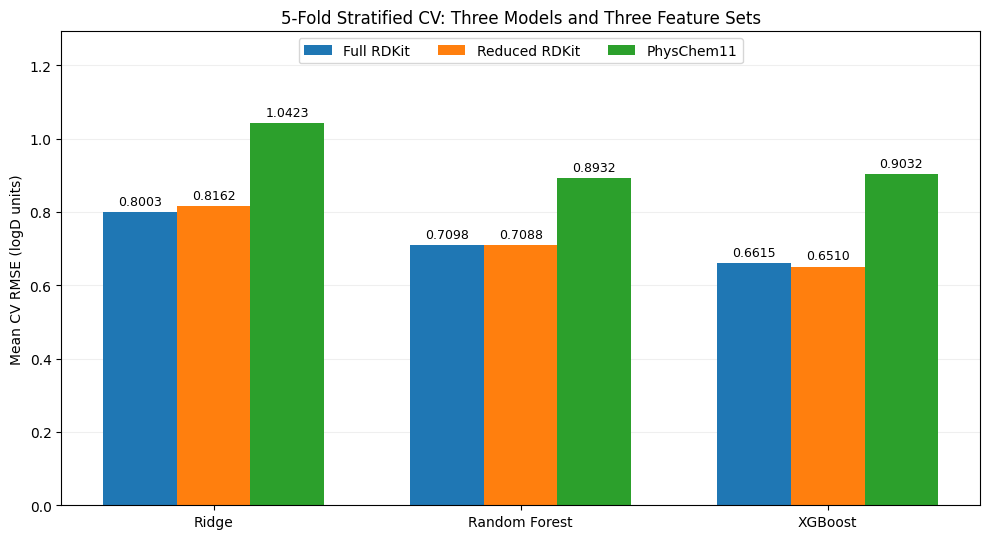

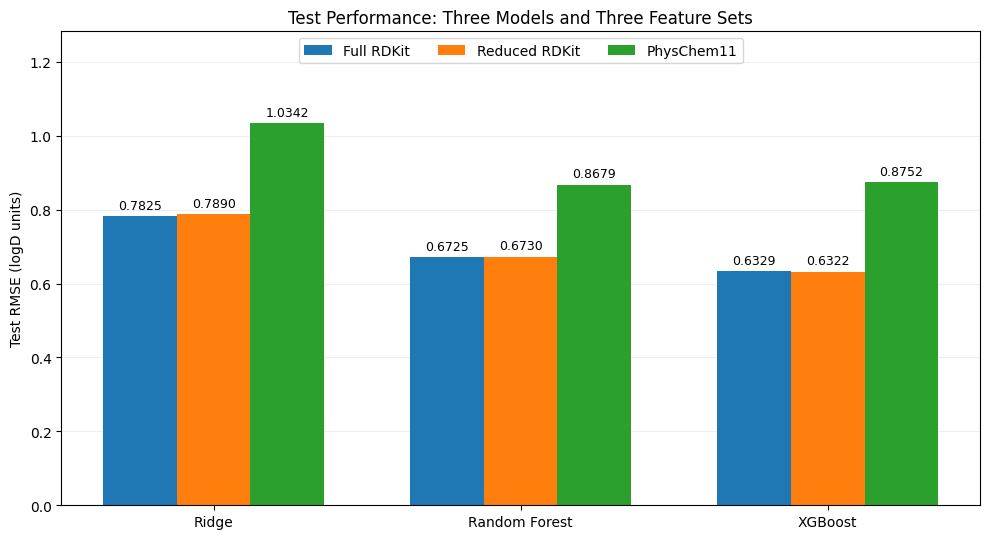

In [39]:
import numpy as np
import matplotlib.pyplot as plt

model_order = ["Ridge", "Random Forest", "XGBoost"]
feature_order = ["Full RDKit", "Reduced RDKit", "PhysChem11"]
x = np.arange(len(model_order))
width = 0.24

# Draw separate figures for CV and test performance
for metric, title, filename in [
    ("CV_RMSE", "5-Fold Stratified CV: Three Models and Three Feature Sets",
     "LIPO_Three_Feature_Sets_CV_RMSE.png"),
    ("Test_RMSE", "Test Performance: Three Models and Three Feature Sets",
     "LIPO_Three_Feature_Sets_Test_RMSE.png")
]:
    values = all_model_results.pivot(
        index="Model", columns="Feature_Set", values=metric
    ).loc[model_order, feature_order]
    assert values.notna().all().all()

    fig, ax = plt.subplots(figsize=(10, 5.5))
    for offset, feature_set in enumerate(feature_order):
        bars = ax.bar(
            x + (offset - 1) * width, values[feature_set], width,
            label=feature_set
        )
        ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)

    ax.set_xticks(x, model_order)
    ax.set_ylabel("Mean CV RMSE (logD units)" if metric == "CV_RMSE"
                  else "Test RMSE (logD units)")
    ax.set_title(title)
    ax.set_ylim(0, float(values.to_numpy().max()) * 1.24)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(ncol=3, loc="upper center")
    fig.tight_layout()
    fig.savefig(output_dir / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 4.4 Reduced RDKit XGBoost — Prediction Error Analysis

We keep the error and importance analyses for Reduced RDKit XGBoost. The overall CV winner is reported in the comparison table. We reuse the test predictions from above and do not use these errors to change the model.


Model analysed: Reduced RDKit XGBoost


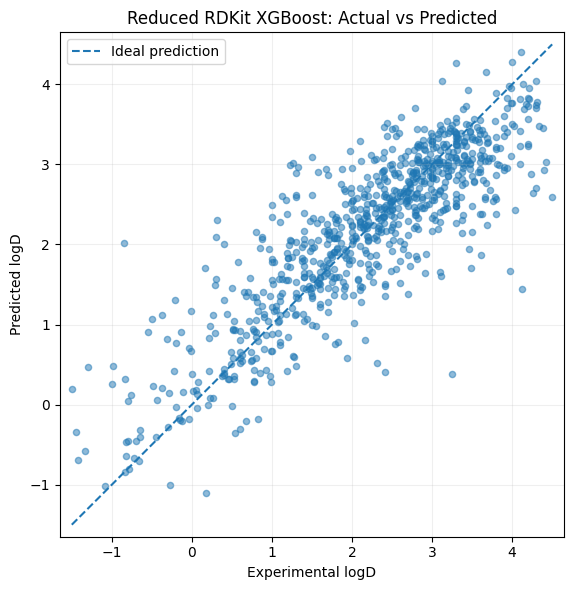

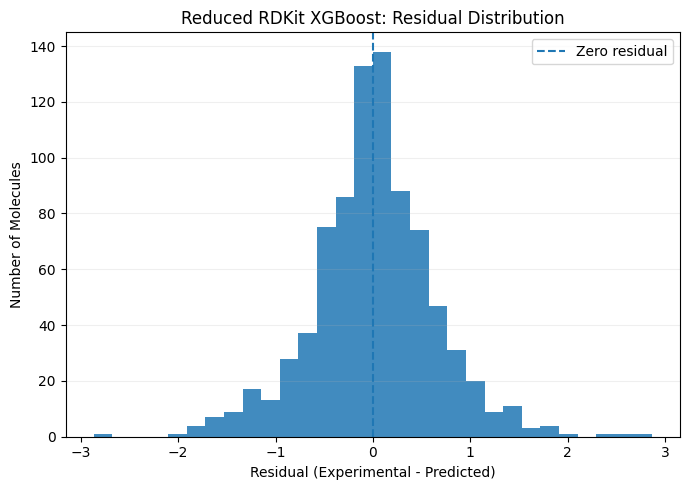

Test molecules: 840
Mean residual: 0.0082
Residual standard deviation: 0.6322
Minimum residual: -2.8681
Maximum residual: 2.8664


In [40]:
# Keep one model reference for all remaining interpretation cells
analysis_name = "XGBoost Reduced"
analysis_label = "Reduced RDKit XGBoost"
final_model = model_searches[analysis_name].best_estimator_
assert "reduce_correlation" in final_model.named_steps
assert "xgb" in final_model.named_steps

print("Model analysed:", analysis_label)
if cv_selected_name != analysis_name:
    print("Note: the current overall CV winner is", cv_selected_name,
          ". The following analysis still describes Reduced RDKit XGBoost.")

# Reuse predictions from the combined test evaluation
actual = test_predictions["exp"].to_numpy(dtype=float)
predicted = test_predictions[analysis_name].to_numpy(dtype=float)
residuals = actual - predicted

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(actual, predicted, alpha=0.5, s=20)
lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())
ax.plot([lower, upper], [lower, upper], "--", label="Ideal prediction")
ax.set_xlim(lower - 0.15, upper + 0.15)
ax.set_ylim(lower - 0.15, upper + 0.15)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Experimental logD")
ax.set_ylabel("Predicted logD")
ax.set_title(f"{analysis_label}: Actual vs Predicted")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(output_dir / "LIPO_Reduced_XGBoost_Actual_vs_Predicted.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(residuals, bins=30, alpha=0.85)
ax.axvline(0, linestyle="--", label="Zero residual")
ax.set_xlabel("Residual (Experimental - Predicted)")
ax.set_ylabel("Number of Molecules")
ax.set_title(f"{analysis_label}: Residual Distribution")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(output_dir / "LIPO_Reduced_XGBoost_Residual_Distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Test molecules:", len(actual))
print("Mean residual:", round(float(residuals.mean()), 4))
print("Residual standard deviation:", round(float(residuals.std()), 4))
print("Minimum residual:", round(float(residuals.min()), 4))
print("Maximum residual:", round(float(residuals.max()), 4))


## 4.5 Validation-Fold Permutation Importance

We refit the selected Reduced RDKit XGBoost model in each CV fold. Constant removal and correlation reduction use only that fold's training data.

We then shuffle one retained descriptor in the validation data and measure the increase in RMSE. A larger increase means that the descriptor is more useful for these predictions. We do not use the test set.

`Folds` shows how many fold models retained the descriptor. We calculate the mean and standard deviation using those folds. Correlated descriptors may share useful information, so a small importance does not prove that a chemical property is unimportant. We use these scores to explain the model, not to select another feature set.


Reduced XGBoost permutation importance: fold 1 completed.
Reduced XGBoost permutation importance: fold 2 completed.
Reduced XGBoost permutation importance: fold 3 completed.
Reduced XGBoost permutation importance: fold 4 completed.
Reduced XGBoost permutation importance: fold 5 completed.

Reduced RDKit XGBoost: Top 15 Permutation Importances


,Descriptor,Mean_RMSE_Increase,Fold_Std,Folds
0,MolLogP,0.4355,0.0296,5
1,fr_COO,0.2508,0.0288,5
2,SlogP_VSA10,0.0196,0.0063,5
3,PEOE_VSA13,0.0190,0.0036,5
4,VSA_EState5,0.0174,0.0043,5
5,SMR_VSA10,0.0157,0.0047,5
6,NHOHCount,0.0154,0.0034,5
7,BalabanJ,0.0097,0.0059,5
8,SlogP_VSA2,0.0091,0.0029,5
9,fr_Al_COO,0.0085,0.0066,5


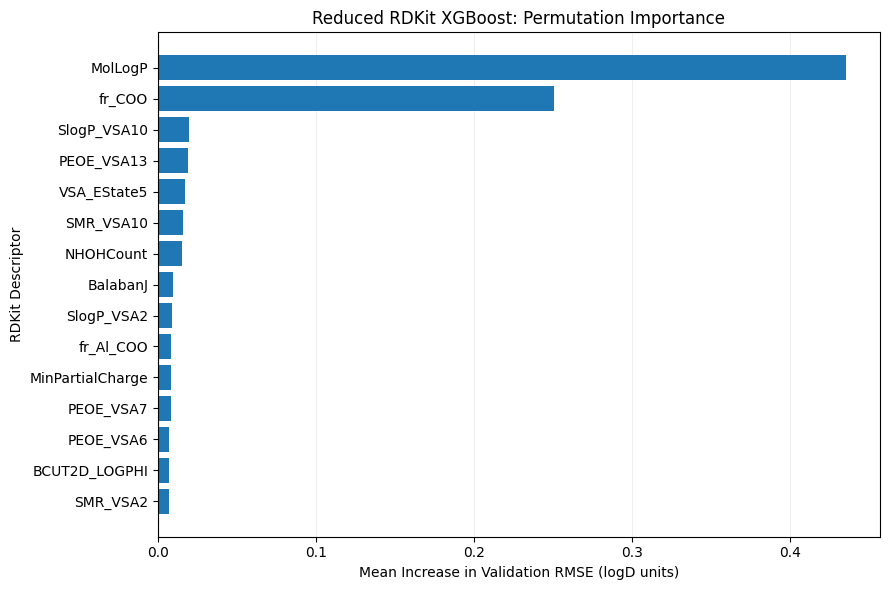

In [42]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.inspection import permutation_importance

permutation_results = []

for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
    # Refit the complete pipeline using only this fold's fitting molecules
    fold_model = clone(final_model)
    fold_model.fit(X_train_raw.iloc[fit_idx], y_train.iloc[fit_idx])

    # Check molecular row separation; scaffold separation is not required here
    assert np.intersect1d(fit_idx, valid_idx).size == 0

    # Use fitted preprocessing without refitting it on validation data
    X_valid = fold_model[:-1].transform(X_train_raw.iloc[valid_idx])
    y_valid = y_train.iloc[valid_idx]
    names = retained_descriptor_names(fold_model, X_train_raw.columns)
    assert X_valid.shape[1] == len(names)

    importance = permutation_importance(
        fold_model.named_steps["xgb"],
        X_valid,
        y_valid,
        scoring="neg_root_mean_squared_error",
        n_repeats=3,
        max_samples=1.0,
        random_state=42 + fold,
        n_jobs=1
    )

    for name, value in zip(names, importance.importances_mean):
        permutation_results.append({
            "Fold": fold,
            "Descriptor": name,
            "RMSE_Increase": value
        })

    print(f"Reduced XGBoost permutation importance: fold {fold} completed.")

permutation_df = pd.DataFrame(permutation_results)
permutation_summary = (
    permutation_df.groupby("Descriptor")
    .agg(
        Mean_RMSE_Increase=("RMSE_Increase", "mean"),
        Fold_Std=("RMSE_Increase", "std"),
        Folds=("Fold", "nunique")
    )
    .reset_index()
    .sort_values("Mean_RMSE_Increase", ascending=False)
    .reset_index(drop=True)
)

print("\nReduced RDKit XGBoost: Top 15 Permutation Importances")
display(permutation_summary.head(15).round(4))

top15 = permutation_summary.head(15).sort_values("Mean_RMSE_Increase")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top15["Descriptor"], top15["Mean_RMSE_Increase"])
ax.axvline(0, linestyle="--")
ax.set_xlabel("Mean Increase in Validation RMSE (logD units)")
ax.set_ylabel("RDKit Descriptor")
ax.set_title(f"{analysis_label}: Permutation Importance")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(output_dir / "LIPO_Reduced_XGBoost_Permutation_Importance.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

permutation_df.to_csv(
    output_dir / "LIPO_Reduced_XGBoost_Permutation_All_Folds.csv", index=False
)
permutation_summary.to_csv(
    output_dir / "LIPO_Reduced_XGBoost_Permutation_Summary.csv", index=False
)
